# clean notebook for comparing the two method which are ind gp and vanilla bo

In [2]:
import os
import sys
import json
import shutil
import pprint
import time
from pathlib import Path

base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
if str(base_path) not in sys.path:
    sys.path.insert(0, str(base_path))
os.chdir(base_path)

os.environ['SUMO_HOME'] = '/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo'
os.environ['LIBSUMO_AS_TRACI'] = '1'
SUMO_HOME = Path(os.environ['SUMO_HOME'])

if "SUMO_HOME" in os.environ:
    tools = os.path.join(os.environ["SUMO_HOME"], "tools")
    sys.path.append(tools)
else:
    sys.exit("Please declare the environment variable 'SUMO_HOME'")

SUMO_ROOT = Path(os.environ["SUMO_HOME"]).parents[1]
SUMO_BIN = str(SUMO_ROOT / "bin")
LIB_SUMO_PATH = Path(os.environ["SUMO_HOME"]).parents[2] / "lib" / "libsumo.dylib"
os.environ["PATH"] = SUMO_BIN + os.pathsep + os.environ.get("PATH", "")

import traci
import sumolib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy import stats
from torch.quasirandom import SobolEngine

from botorch.acquisition import ExpectedImprovement, qLogExpectedImprovement
from botorch.exceptions import ModelFittingError
from botorch.fit import fit_gpytorch_mll
from botorch.models import SingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.optim import optimize_acqf
from botorch.sampling.stochastic_samplers import StochasticSampler
from botorch.utils.transforms import normalize, unnormalize
from gpytorch.constraints import Interval
from gpytorch.kernels import MaternKernel, ScaleKernel
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.mlls import ExactMarginalLogLikelihood
from gpytorch.settings import max_cholesky_size
from gpytorch.utils.errors import NotPSDError

from src.models.gp_models import (
    initialize_independent_gp_models_with_modellist,
    make_linear_aggregation_model_from_error_gps,
    extract_independent_gp_hyperparameters,
    initialize_vanillabo_model,
)
from src.utils.seed import set_seed
from src.simulation.sumo_runner import (
    create_od_xml,
    create_taz_xml,
    simulate_od,
    parse_loop_data_xml_to_pandas,
)


from src.simulation.data_loader import (od_xml_to_df,
                                        load_kwargs_config)
from src.utils.link_flow_analysis import (
    compute_squared_metric_all_edge as compute_squared_metric_all_edge,
    compute_squared_metric_per_edge as compute_squared_metric_per_edge,
)

from src.utils.edge_flow_grouping import group_edge_dataframe, get_representative_edges

%matplotlib inline

config = load_kwargs_config(base_path, "bo_vanilla")
Path(config["simulation_run_path"]).mkdir(parents=True, exist_ok=True)
pprint.pprint(dict(config))

{'BATCH_SIZE': 1,
 'BO_batch_size': 1,
 'BO_niter': 100,
 'BO_num_restarts': 10,
 'BO_raw_samples': 128,
 'BO_sample_shape': 128,
 'CLEANUP_INTERMEDIATE_FILES': True,
 'EARLY_STOP_DELTA': 0.001,
 'EARLY_STOP_MIN_ACQ': 0.0,
 'EARLY_STOP_PATIENCE': 10,
 'EDGE_OUT_STR': 'edge_data_quickstart.xml',
 'NITER': 100,
 'NUM_RESTARTS': 10,
 'RAW_SAMPLES': 128,
 'SAMPLE_SHAPE': 128,
 'SUMO_PATH': PosixPath('/Library/Frameworks/EclipseSUMO.framework/Versions/1.24.0/EclipseSUMO/share/sumo'),
 'TRIPS2ODS_OUT_STR': 'trips.xml',
 'additional_xml': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml'),
 'dim_od': 4,
 'file_gt_od': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/od.xml'),
 'fixed_routes': PosixPath('/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/routes.csv'),
 'kernel': 'matern-2p5',
 'model_name': 'bo_vanilla',
 'n_init_search': 10,
 'net_xml': PosixPath('/Users/inesbenhamza/Desktop/Sumo

# GT data

In [3]:
# Get Ground Truth OD + fixed routes
print(f"Reading: {config['file_gt_od']}")
gt_od_df = od_xml_to_df(config["file_gt_od"])

print(f"Reading: {config['fixed_routes']}")
routes_df = pd.read_csv(config["fixed_routes"], index_col=0)

Reading: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/od.xml
Total GT demand: 2800.0
Reading: /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/routes.csv


In [4]:
# gt od vector

simulation_gt_run_path =f'{config["simulation_run_path"]}/ground_truth'
prefix_output_gt = f'{simulation_gt_run_path}/sim'
sim_edge_out_gt = f'{prefix_output_gt}_{config["EDGE_OUT_STR"]}'
new_od_xml = f'{simulation_gt_run_path}/od.xml'

Path(simulation_gt_run_path).mkdir(parents=True, exist_ok=True)

base_od = gt_od_df.copy()
gt_od_vals = gt_od_df['count'].astype(float).to_numpy()
curr_od = gt_od_vals.copy()
base_od['count'] = curr_od
base_od = base_od.rename(columns={'fromTaz':'from', 'toTaz':'to'})
create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

print(base_od)


# Run simulation
simulate_od(new_od_xml,
            prefix_output_gt,
            base_path,
            config["net_xml"],
            config["taz2edge_xml"],
            config["additional_xml"],
            routes_df,
            config["sim_end_time"],
            config["TRIPS2ODS_OUT_STR"])

Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ground_truth/od.xml
    from     to  count
0  taz91  taz93  500.0
1  taz91  taz94  500.0
2  taz92  taz93  900.0
3  taz92  taz94  900.0
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_bo_vanilla_matern-2p5/ground_truth/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ground_truth/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ground_truth/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ground_truth/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/net

In [5]:
# gt link flow

df_edge_gt, df_trips_raw, out_csv = parse_loop_data_xml_to_pandas(
    base_path,
    sim_edge_out_gt,  
    prefix_output_gt, 
    config["SUMO_PATH"],
)

print(df_edge_gt.head())
print(df_trips_raw.columns)

num_gt_edges = df_edge_gt.shape[0]
print("Number of GT edges:",num_gt_edges)

  edge_id  interval_nVehContrib  interval_harmonicMeanSpeed
0      D2                1000.0                    8.445000
1      D4                1800.0                    8.527143
2      D5                1400.0                   11.488750
3      D7                1400.0                   11.294444
4     L10                1400.0                   11.441250
Index(['interval_begin', 'interval_end', 'interval_id', 'edge_arrived',
       'edge_density', 'edge_departed', 'edge_entered', 'edge_id',
       'edge_laneChangedFrom', 'edge_laneChangedTo', 'edge_laneDensity',
       'edge_left', 'edge_occupancy', 'edge_overlapTraveltime',
       'edge_sampledSeconds', 'edge_speed', 'edge_speedRelative',
       'edge_timeLoss', 'edge_traveltime', 'edge_waitingTime',
       'interval_nVehContrib', 'interval_harmonicMeanSpeed'],
      dtype='object')
Number of GT edges: 14


In [6]:
print(df_edge_gt.head(30))

   edge_id  interval_nVehContrib  interval_harmonicMeanSpeed
0       D2                1000.0                    8.445000
1       D4                1800.0                    8.527143
2       D5                1400.0                   11.488750
3       D7                1400.0                   11.294444
4      L10                1400.0                   11.441250
5      L12                1000.0                   11.410000
6      L14                1800.0                   11.386250
7      L15                 500.0                   12.054000
8      L16                 900.0                   11.863750
9      L18                1400.0                   11.635000
10      L2                1000.0                   10.498000
11      L4                1800.0                    9.915000
12      L5                1400.0                   11.353750
13      L7                1400.0                   11.046667


# adding uniform weight

In [7]:
from src.utils.edge_flow_grouping import (
    get_representative_edges,
    group_edge_dataframe,
)

# Group ALL edges first, then get representative edge IDs
gt_edge_grouped = group_edge_dataframe(df_edge_gt)
edge_ids = get_representative_edges()

# Pull out the ground-truth flow values for the representative edges
gt_flows = gt_edge_grouped.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)

print(gt_edge_grouped)

L = len(edge_ids)   # 6 groups
weights_np = np.ones(L) / L

print("Using uniform weights:")
for e, w in zip(edge_ids, weights_np):
    print(f"  {e}: weight = {w:.4f}")

  edge_id  interval_nVehContrib
0     L12                1000.0
1     L14                1800.0
2     L18                1400.0
3     L10                1400.0
4     L15                 500.0
5     L16                 900.0
Using uniform weights:
  L12: weight = 0.1667
  L14: weight = 0.1667
  L18: weight = 0.1667
  L10: weight = 0.1667
  L15: weight = 0.1667
  L16: weight = 0.1667


# bound

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
dtype = torch.double

dim_od = gt_od_df.shape[0]  # dimension of the OD vector (e.g. 4)
print(dim_od)
d = dim_od  # alias so later cells can use d
# d= config.get("dim_od",4)

# Bounds from config — defined once here
od_bound_start = config.get("od_bound_start", 1)
od_bound_end = config.get("od_bound_end", 2000)
bounds = torch.stack([
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])
bounds_norm = torch.stack([
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])

seed = 42
set_seed(seed)

print(f"Random seed set to {seed}")
print(f"OD bounds: [{od_bound_start}, {od_bound_end}]")

cpu
4
Random seed set to 42
OD bounds: [1, 2000]


# sobol point 

In [14]:
sobol = SobolEngine(dim_od, scramble=True, seed = seed)
#x_0 = sobol.draw(config["n_init_search"]).to(dtype=dtype).to(device)
x_0 = sobol.draw(10).to(dtype=dtype).to(device) # in normalized space
print (x_0.shape)
print (x_0)
# map the normalized into the original parameter space
train_X0 = unnormalize(x_0, bounds)
print (train_X0) 
print (dim_od)

torch.Size([10, 4])
tensor([[0.9975, 0.1044, 0.8230, 0.4194],
        [0.4527, 0.8381, 0.0733, 0.6162],
        [0.2182, 0.3502, 0.6979, 0.1740],
        [0.7320, 0.5843, 0.4483, 0.8532],
        [0.5862, 0.3903, 0.1549, 0.9096],
        [0.1042, 0.6869, 0.9054, 0.1181],
        [0.3695, 0.1287, 0.2800, 0.6837],
        [0.8210, 0.9249, 0.5303, 0.3512],
        [0.7693, 0.2952, 0.3172, 0.0505],
        [0.2824, 0.5299, 0.5678, 0.9768]], dtype=torch.float64)
tensor([[1995.0292,  209.6284, 1646.1347,  839.4449],
        [ 905.9491, 1676.2965,  147.4677, 1232.7237],
        [ 437.1494,  701.0950, 1396.1556,  348.7578],
        [1464.2525, 1169.0097,  897.1643, 1706.5583],
        [1172.8789,  781.2135,  310.6750, 1819.3277],
        [ 209.2215, 1374.0469, 1810.8826,  237.1627],
        [ 739.5444,  258.3555,  560.6994, 1367.8132],
        [1642.1934, 1849.9723, 1061.0794,  703.0590],
        [1538.8719,  591.1922,  635.0926,  102.0245],
        [ 565.5081, 1060.3233, 1136.0275, 1953.7186]

### evaluation of sobol point using squared metrics

using the initial data point, ismulating flow on each edge and computing the aggregated error

In [9]:
from typing import Any

csv_path = Path(f"{config['simulation_run_path']}/initial_search/squared/data_set_ods_10_squared.csv")

if csv_path.exists():
    print(f"Loading initial data from {csv_path}")
    df_initial_bo = pd.read_csv(csv_path)

    x_cols = [col for col in df_initial_bo.columns if col.startswith("x_")]
    x_cols.sort(key=lambda x: int(x.split("_")[1]))
    e_cols = [col for col in df_initial_bo.columns if col.startswith("e_")]

    train_X_list = []
    train_E_list = []
    S_list = []

    for _, row in df_initial_bo.iterrows():
        train_X_list.append(row[x_cols].values.astype(float))
        train_E_list.append(row[e_cols].values.astype(float))
        S_list.append(float(row["loss"]))

    print(f"  Loaded {len(train_X_list)} initial points")
    print(f"  OD dimension: {len(x_cols)}, Edges: {len(e_cols)}")

else:
    train_X_list = []
    train_E_list = []
    S_list = []

    batch_data_i = []

    N_REP = 1

    for i, x in enumerate(train_X0.tolist()):
        print(f"Initial OD: {i}")
        curr_od = np.array(x, dtype=float)
        print(curr_od)
        print(f"total expected demand: {np.sum(curr_od)}")

        simulation_run_path_init = f"{config['simulation_run_path']}/initial_search/squared"
        Path(simulation_run_path_init).mkdir(parents=True, exist_ok=True)

        new_od_xml = f"{simulation_run_path_init}/gt_od_{config['network_name']}_{i}.xml"
        prefix_output_base = f"{simulation_run_path_init}/sobol_{i}"

        base_od = gt_od_df.copy()
        base_od["count"] = curr_od
        base_od["count"] = [round(v, 1) for v in base_od["count"]]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(new_od_xml, base_od, config["od_duration_sec"], base_path)

        per_edge_errors_reps = []
        for rep in range(N_REP):
            print(f" Replication {rep}")
            prefix_output_rep = f"{prefix_output_base}_rep{rep}"

            simulate_od(
                new_od_xml,
                prefix_output_rep,
                base_path,
                config["net_xml"],
                config["taz2edge_xml"],
                config["additional_xml"],
                routes_df,
                config["sim_end_time"],
                config["TRIPS2ODS_OUT_STR"],
                sim_start_time=0,
                seed=rep,
            )

            sim_edge_out_rep = f"{prefix_output_rep}_{config['EDGE_OUT_STR']}"
            curr_loop_stats_rep, _, _ = parse_loop_data_xml_to_pandas(
                base_path,
                sim_edge_out_rep,
                prefix_output_rep,
                config["SUMO_PATH"],
            )

            curr_loop_stats_rep_grouped = group_edge_dataframe(curr_loop_stats_rep)
            sim_counts = curr_loop_stats_rep_grouped.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values

            print(f"\n--- Simulated flows for replication {rep} ---")
            for edge_id, count in zip(edge_ids, sim_counts):
                print(f"  {edge_id}: {count}")

            per_edge_errors_rep = compute_squared_metric_per_edge(
                df_true=gt_edge_grouped,
                df_simulated=curr_loop_stats_rep_grouped,
                edge_ids=edge_ids,
            )

            per_edge_errors_reps.append(per_edge_errors_rep)

        per_edge_errors_reps = np.stack(per_edge_errors_reps, axis=0)
        per_edge_errors = per_edge_errors_reps.mean(axis=0)

        S_x = float((per_edge_errors * weights_np).sum())
        print(f"aggregated loss S(x): {S_x}")

        train_X_list.append(curr_od.copy())
        train_E_list.append(per_edge_errors.copy())
        S_list.append(S_x)

        df_curr = pd.DataFrame(
            curr_od.reshape(1, -1),
            columns=[f"x_{k+1}" for k in range(curr_od.shape[0])]
        )
        df_curr["loss"] = S_x

        for edge_idx, edge_id in enumerate(edge_ids):
            df_curr[f"e_{edge_id}"] = per_edge_errors[edge_idx]

        batch_data_i.append(df_curr)

    if batch_data_i:
        df_initial_bo = pd.concat(batch_data_i, ignore_index=True)
        df_initial_bo.to_csv(csv_path, index=False)
        print(f"✓ Saved initial data to {csv_path}")


Loading initial data from output/quickstart_bo_vanilla_matern-2p5/initial_search/squared/data_set_ods_10_squared.csv
  Loaded 10 initial points
  OD dimension: 4, Edges: 6


In [9]:
print("L (number of outputs):", L)
print("edge_ids:", edge_ids)
print("weights_np:", weights_np)
print("len(edge_ids) == L:", len(edge_ids) == L)

L (number of outputs): 6
edge_ids: ['L12', 'L14', 'L18', 'L10', 'L15', 'L16']
weights_np: [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
len(edge_ids) == L: True


# devices

In [10]:
dtype  = torch.double  
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_X = torch.tensor(np.array(train_X_list),
                       dtype=dtype, device=device)  # converting the training point as a tensor 

# Y is the aggregated scalar loss per sample as its the global qtt we want to min 
train_Y = torch.tensor(np.array(S_list), 
                       dtype=dtype, device=device).unsqueeze(-1)  # also converting it as a tensor 


In [11]:
print("train_X.shape:", train_X.shape)
print("train_Y.shape:", train_Y.shape)
print("First 3 train_Y (scalar loss):", train_Y[:3].cpu().numpy().ravel())

train_X.shape: torch.Size([10, 4])
train_Y.shape: torch.Size([10, 1])
First 3 train_Y (scalar loss): [2.19444754 0.76242015 0.09480456]


## Scalar GP  -- predicition time and inference in BO 

In [11]:
dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_X = train_X.to(device=device, dtype=dtype)
train_Y = train_Y.to(device=device, dtype=dtype)
N, d = train_X.shape
assert train_Y.shape == (N, 1), f"train_Y must be [N, 1], got {train_Y.shape}"

assert train_X.min() >= od_bound_start and train_X.max() <= od_bound_end, (
    f"train_X should be in [{od_bound_start}, {od_bound_end}]; got min={train_X.min():.2f}, max={train_X.max():.2f}. "
    "Use same bounds in the initial-data (Sobol) cell."
)

train_X_van_init = train_X.clone()
train_Y_van_init = train_Y.clone()

N_RESTARTS = 12
N_BO_ITERS = 200
kernel = "matern-2p5"
BO_FOLDER = "ScalarGP"
NOISE_LABEL = "noise_1e-4_1"

use_early_stop = config.get("EARLY_STOP_ENABLED", False)
EARLY_STOP_PATIENCE = config.get("EARLY_STOP_PATIENCE", 0) if use_early_stop else 0
EARLY_STOP_DELTA = config.get("EARLY_STOP_DELTA", 1e-6)
EARLY_STOP_MIN_ACQ = config.get("EARLY_STOP_MIN_ACQ", 0.0)

skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)

save_base = Path(config["simulation_run_path"]) / BO_FOLDER / NOISE_LABEL / "NEW"
save_base.mkdir(parents=True, exist_ok=True)
results_dir = save_base / "results"
results_dir.mkdir(parents=True, exist_ok=True)

import xml.etree.ElementTree as _ET


def _load_vanilla_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                         best_S_init, gt_od_df, gt_edge_grouped,
                         edge_ids, device, dtype):
    train_X = train_X_init.clone()
    train_Y = train_Y_init.clone()
    best_S = best_S_init
    S_hist = [best_S_init]
    start_iter = 0
    for _it in range(n_bo_iters):
        loop_csv = sim_base / f"iter_{_it}" / "sim_loopOutputs.csv"
        od_xml   = sim_base / f"iter_{_it}" / "od.xml"
        if not loop_csv.exists() or not od_xml.exists():
            break
        tree = _ET.parse(str(od_xml))
        root = tree.getroot()
        rows = [el.attrib for el in root.iter("tazRelation")]
        _counts = pd.DataFrame(rows)["count"].astype(float).values
        _x = torch.tensor(_counts, device=device, dtype=dtype).view(1, -1)
        _df = pd.read_csv(str(loop_csv), sep=";")
        _df["interval_nVehContrib"] = _df["edge_arrived"] + _df["edge_left"]
        _df["interval_harmonicMeanSpeed"] = _df["edge_speed"]
        _df_agg = _df.groupby("edge_id", as_index=False).agg(
            interval_nVehContrib=("interval_nVehContrib", "sum"),
            interval_harmonicMeanSpeed=("interval_harmonicMeanSpeed", "mean"),
        )
        _grp = group_edge_dataframe(_df_agg)
        _loss = float(np.asarray(compute_squared_metric_all_edge(
            gt_edge_grouped, _grp, edge_ids
        )).flat[0])
        _y = torch.tensor([[_loss]], device=device, dtype=dtype)
        train_X = torch.cat([train_X, _x], dim=0)
        train_Y = torch.cat([train_Y, _y], dim=0)
        if _loss < best_S:
            best_S = _loss
        S_hist.append(best_S)
        start_iter = _it + 1
    return train_X, train_Y, best_S, S_hist, start_iter


vanilla_histories_raw = []

for r in range(N_RESTARTS):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    convergence_file = restart_dir / "convergence.csv"

    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        vanilla_histories_raw.append(S_history)
        print(f"\n VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(restart_seed)
    print(f"\n VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")

    best_S_init = train_Y_van_init.min().item()
    sim_base = Path(save_base) / f"restart_{r+1}_seed-{restart_seed}"
    train_X_van, train_Y_van, best_S_raw, S_history_raw, start_iter = _load_vanilla_iters(
        sim_base, N_BO_ITERS,
        train_X_van_init, train_Y_van_init,
        best_S_init, gt_od_df, gt_edge_grouped,
        edge_ids, device, dtype,
    )
    best_checkpoint = best_S_raw
    no_improve_steps = 0

    if start_iter > 0:
        print(f"[RESUME] Loaded {start_iter} iters → resuming from iter {start_iter+1}/{N_BO_ITERS}, best S={best_S_raw:.6f}")
    else:
        print(f"[INIT] N={train_X_van.shape[0]}, best S (raw) = {best_S_raw:.6f}")
    if EARLY_STOP_PATIENCE > 0:
        print(f"  EARLY STOP: patience={EARLY_STOP_PATIENCE}, delta={EARLY_STOP_DELTA:.6e}")

    for it in range(start_iter, N_BO_ITERS):
        iter_t0 = time.time()

        # GP: fit on current (X, S) and get posterior
        train_X_norm = normalize(train_X_van, bounds=bounds)
        model = initialize_vanillabo_model(train_X_norm, train_Y_van, kernel=kernel).to(device=device, dtype=dtype)
        mll = ExactMarginalLogLikelihood(model.likelihood, model)
        fit_gpytorch_mll(mll)
        model.eval()

        # --- Residual diagnostic ---
        with torch.no_grad():
            posterior_mean = model.posterior(train_X_norm).mean  # [n, 1]
        residuals = train_Y_van - posterior_mean
        relative_error = residuals.abs() / train_Y_van.abs()
        mean_rel_err = relative_error.mean().item()
        noise_val    = model.likelihood.noise.item()
        output_val   = model.covar_module.outputscale.item()
        ls_vals      = model.covar_module.base_kernel.lengthscale.detach().squeeze().cpu().numpy()
        if ls_vals.ndim == 0:
            ls_vals = np.array([float(ls_vals)])
        print(f"  [RESIDUAL] mean rel error: {mean_rel_err:.4f}  noise: {noise_val:.6f}  outputscale: {output_val:.6f}  ratio: {noise_val/output_val:.4f}  ls_mean: {ls_vals.mean():.4f}")

        diag_path = restart_dir / "gp_diagnostics.csv"
        restart_dir.mkdir(parents=True, exist_ok=True)
        diag_row = pd.DataFrame([{
            "iteration":          it,
            "mean_rel_error":     mean_rel_err,
            "noise":              noise_val,
            "outputscale":        output_val,
            "noise_signal_ratio": noise_val / output_val,
            "lengthscale_mean":   float(ls_vals.mean()),
            "lengthscale_min":    float(ls_vals.min()),
            "lengthscale_max":    float(ls_vals.max()),
            **{f"lengthscale_dim_{i}": float(ls_vals[i]) for i in range(len(ls_vals))},
            "n_train":            train_X_van.shape[0],
            "best_S":             best_S_raw,
        }])

        diag_row.to_csv(diag_path, mode="a", header=not diag_path.exists(), index=False)

        # EI
        best_f_for_ei = train_Y_van.min()
        acquisition_function = ExpectedImprovement(model=model, best_f=best_f_for_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            acq_function=acquisition_function,
            bounds=bounds_norm,
            q=1,
            num_restarts=config.get("BO_num_restarts", 10),
            raw_samples=config.get("BO_sample_shape", 128),
        )
        x_next_norm = x_next_norm.detach()
        x_next_real = unnormalize(x_next_norm, bounds).view(-1).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        # sim directory and OD file
        sim_dir = save_base / f"restart_{r+1}_seed-{restart_seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        new_od_xml = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)

        # SUMO simulation
        t0 = time.time()
        simulate_od(
            str(new_od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
        )
        print(f"[RUNTIME] Simulation took {time.time() - t0:.2f}s")

        # Parse outputs and compute scalar loss S(x_next)
        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )
        curr_loop_stats_grouped = group_edge_dataframe(curr_loop_stats)
        curr_loss = compute_squared_metric_all_edge(
            gt_edge_grouped, curr_loop_stats_grouped, edge_ids
        )
        curr_loss = float(np.asarray(curr_loss).flat[0])

        # Update best S and history
        if curr_loss < best_S_raw:
            best_S_raw = curr_loss
            print(f"[UPDATE] New BEST S = {best_S_raw:.6f}")
        else:
            print(f"[NO IMPROVEMENT] Best S remains {best_S_raw:.6f}")
        S_history_raw.append(best_S_raw)

        # Append (x_next, S(x_next)) to training set
        train_X_van = torch.cat([
            train_X_van,
            torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1),
        ], dim=0)
        train_Y_van = torch.cat([
            train_Y_van,
            torch.tensor([[curr_loss]], device=device, dtype=dtype),
        ], dim=0)

        # Save per-iteration artifacts
        merged_data = pd.merge(
            gt_edge_grouped[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id",
            suffixes=("_gt", "_sim"),
        )
        merged_data.to_csv(sim_dir / "link_measure_compare.csv", index=False)
        (sim_dir / f"LOSS_{curr_loss:.6f}.txt").write_text(f"LOSS: {curr_loss:.6f}")
        if config.get("CLEANUP_INTERMEDIATE_FILES", False):
            try:
                if Path(sim_edge_out).exists():
                    Path(sim_edge_out).unlink()
            except Exception as e:
                print(f"[Warning] Cleanup: {e}")

        # Early stopping
        if EARLY_STOP_PATIENCE > 0:
            delta = best_checkpoint - best_S_raw
            if delta >= EARLY_STOP_DELTA:
                best_checkpoint = best_S_raw
                no_improve_steps = 0
            else:
                no_improve_steps += 1
                if no_improve_steps >= EARLY_STOP_PATIENCE:
                    print(f"\nEARLY STOP: no improvement ≥ {EARLY_STOP_DELTA} for {EARLY_STOP_PATIENCE} iters. Best S: {best_S_raw:.6f}\n")
                    break
        if EARLY_STOP_MIN_ACQ > 0 and acq_val.item() < EARLY_STOP_MIN_ACQ:
            print(f"\nEARLY STOP: EI < {EARLY_STOP_MIN_ACQ}. Best S: {best_S_raw:.6f}\n")
            break

        iter_elapsed = time.time() - iter_t0
        print(f"[BO iter {it+1}/{N_BO_ITERS}] S(x_next)={curr_loss:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}, time={iter_elapsed:.2f}s")

    vanilla_histories_raw.append(S_history_raw)
    print(f"\n[RESTART {r+1} COMPLETE] Final best S = {best_S_raw:.6f}")

    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history_raw)), "best_S": S_history_raw}).to_csv(
        convergence_file, index=False
    )
    print(f"✓ Convergence saved: {convergence_file}")

# Aggregate across restarts
max_len = max(len(h) for h in vanilla_histories_raw)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(vanilla_histories_raw):
    padded[i, :len(h)] = h
mean_curve = np.nanmean(padded, axis=0)
std_curve = np.nanstd(padded, axis=0)
best_S_per_restart = [h[-1] for h in vanilla_histories_raw]
overall_best = min(best_S_per_restart)

print("VANILLA BO COMPLETE")
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)

for r, S_history in enumerate(vanilla_histories_raw):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(
        restart_dir / "convergence.csv", index=False
    )

pd.DataFrame({
    "iteration": range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std": std_curve,
}).to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean": float(np.mean(best_S_per_restart)),
        "best_S_std": float(np.std(best_S_per_restart)),
        "overall_best_S": float(overall_best),
        "n_restarts": N_RESTARTS,
        "n_bo_iters": N_BO_ITERS,
        "n_initial": train_X.shape[0],
        "kernel": kernel,
        "metric": "squared",
        "od_bound_start": od_bound_start,
        "od_bound_end": od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({
    f"restart_{r+1}": vanilla_histories_raw[r] + [np.nan] * (max_len - len(vanilla_histories_raw[r]))
    for r in range(N_RESTARTS)
})
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

print(f"\n✓ Saved: {results_dir}")
print(f"  - restart_X_seed-Y/convergence.csv")
print(f"  - restart_X_seed-Y/gp_diagnostics.csv")
print(f"  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")



 VANILLA BO RESTART 1/12 (seed=42) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000001

 VANILLA BO RESTART 2/12 (seed=1042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000080

 VANILLA BO RESTART 3/12 (seed=2042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000001

 VANILLA BO RESTART 4/12 (seed=3042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000013

 VANILLA BO RESTART 5/12 (seed=4042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000032

 VANILLA BO RESTART 6/12 (seed=5042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000041

 VANILLA BO RESTART 7/12 (seed=6042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000002

 VANILLA BO RESTART 8/12 (seed=7042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000003

 VANILLA BO RESTART 9/12 (seed=8042) — SKIPPED (already saved) ##

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 4 ACT 0 BUF 0)                               
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.09s
 Real time factor: 654545
 UPS: 13909.090909
Vehicles:
 Inserted: 4
 Running: 0
 Waiting: 0
Statistics (avg of 4):
 RouteLength: 4459.95
 Speed: 14.58
 Duration: 306.00
 WaitingTime: 0.00
 TimeLoss: 0.29
 DepartDelay: 0.00
DijkstraRouter answered 4 queries and explored 11.00 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms on average).
[RUNTIME] Simulation took 0.25s
[NO IMPROVEMENT] Best S remains 0.089236
[BO iter 1/200] S(x_next)=0.996976, best S=0.089236, EI=0.873319, time=1.02s
  [RESIDUAL] mean rel error: 0.0007  noise: 0.000100  outputscale: 2.226411  ratio: 0.0000  ls_mean: 2.2328
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/NEW/restart_12_seed-11042/iter_1/od.xml
od2trips --s

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/NEW/restart_12_seed-11042/iter_1/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2248 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.44s
 Real time factor: 131808
 UPS: 3072514.874142
Vehicles:
 Inserted: 2248
 Running: 0
 Waiting: 0
Statistics (avg of 2248):
 RouteLength: 4313.88
 Speed: 7.38
 Duration: 597.28
 WaitingTime: 0.82
 TimeLoss: 282.25
 DepartDelay: 564.95
DijkstraRouter answered 4313 queries and

...

Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2465 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.44s
 Real time factor: 131207
 UPS: 2400198.177677
Vehicles:
 Inserted: 2465
 Running: 0
 Waiting: 0
Statistics (avg of 2465):
 RouteLength: 4525.57
 Speed: 10.62
 Duration: 427.46
 WaitingTime: 0.31
 TimeLoss: 97.00
 DepartDelay: 551.65
DijkstraRouter answered 4761 queries and explored 11.22 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms on average).
[RUNTIME] Simulation took 0.61s
[NO IMPROVEMENT] Best S remains 0.000008
[BO iter 198/200] S(x_next)=0.032977, best S=0.000008, EI=0.000000, time=0.86s
  [RESIDUAL] mean rel error: 0.0104  noise: 0.000100  outputscale: 29.491129  ratio: 0.0000  ls_mean: 3.4242
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/NEW/restart_12_seed-11042/iter_198/

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2484 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.52s
 Real time factor: 109924
 UPS: 2074448.473282
Vehicles:
 Inserted: 2484
 Running: 0
 Waiting: 0
Statistics (avg of 2484):
 RouteLength: 4666.50
 Speed: 10.70
 Duration: 437.61
 WaitingTime: 0.30
 TimeLoss: 96.74
 DepartDelay: 648.35
DijkstraRouter answered 4791 queries and explored 11.82 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms on average).
[RUNTIME] Simulation took 0.69s
[NO IMPROVEMENT] Best S remains 0.000008
[BO iter 199/200] S(x_next)=0.040018, best S=0.000008, EI=0.000000, time=0.92s
  [RESIDUAL] mean rel error: 0.0104  noise: 0.000100  outputscale: 29.667593  ratio: 0.0000  ls_mean: 3.4262
Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/NEW/restart_12_seed-11042/iter_199/

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 3253 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.68s
 Real time factor: 84210.5
 UPS: 1884580.409357
Vehicles:
 Inserted: 3253
 Running: 0
 Waiting: 0
Statistics (avg of 3253):
 RouteLength: 4261.82
 Speed: 10.77
 Duration: 396.26
 WaitingTime: 0.22
 TimeLoss: 84.54
 DepartDelay: 834.79
DijkstraRouter answered 6353 queries and explored 10.16 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms on average).
[RUNTIME] Simulation took 0.87s
[NO IMPROVEMENT] Best S remains 0.000008
[BO iter 200/200] S(x_next)=0.055606, best S=0.000008, EI=0.000000, time=1.18s

[RESTART 12 COMPLETE] Final best S = 0.000008
✓ Convergence saved: output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/NEW/results/restart_12_seed-11042/convergence.csv
VANILLA BO COMPLETE
Restarts: 12, Iterations per restart: 200
Best S per restart: ['

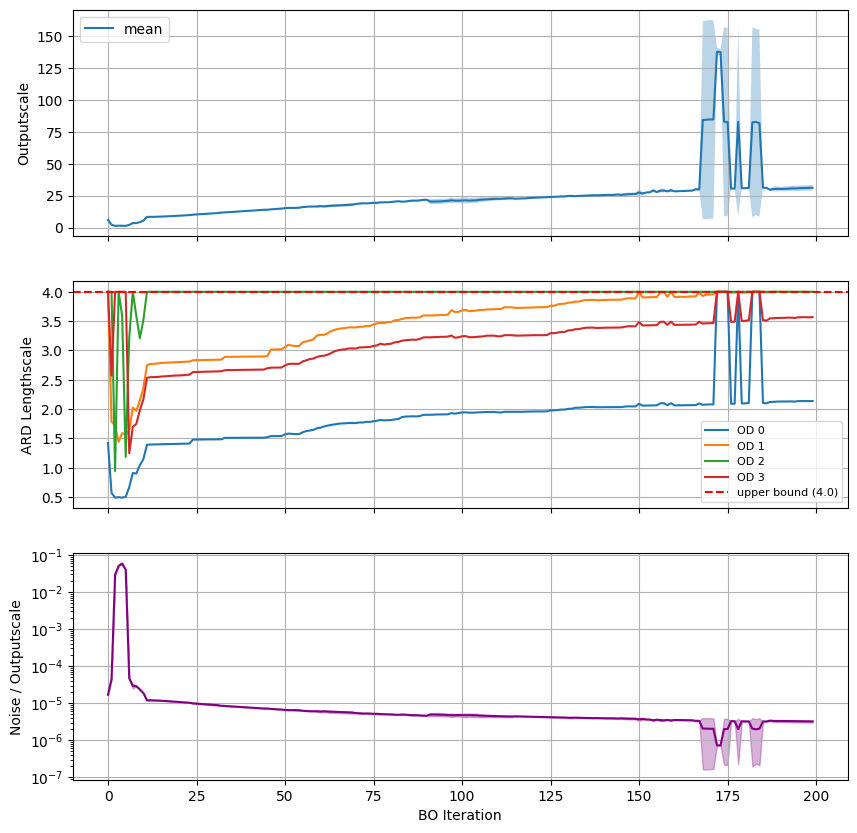

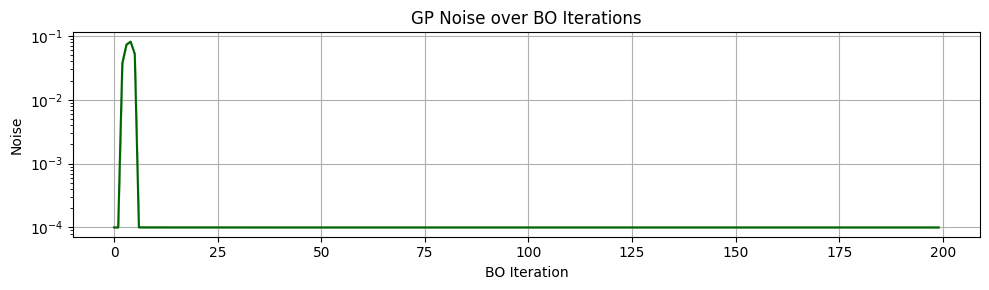

<Figure size 640x480 with 0 Axes>


=== Final iteration hyperparameter summary (mean across restarts) ===
  outputscale: 31.182896
  noise: 0.000100
  lengthscale_mean: 3.426239
  lengthscale_dim_0: 2.138331
  lengthscale_dim_1: 3.999150
  lengthscale_dim_2: 3.999929
  lengthscale_dim_3: 3.567546


In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = save_base / "results"

# Load all restarts
dfs = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    p = results_dir / f"restart_{r+1}_seed-{seed}" / "gp_diagnostics.csv"
    if p.exists():
        df = pd.read_csv(p)
        df["restart"] = r + 1
        dfs.append(df)

all_df = pd.concat(dfs, ignore_index=True)

# Mean ± std across restarts per iteration
grouped = all_df.groupby("iteration")
mean_df = grouped.mean(numeric_only=True)
std_df  = grouped.std(numeric_only=True)

iters = mean_df.index

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

# 1. Outputscale
axes[0].plot(iters, mean_df["outputscale"], label="mean")
axes[0].fill_between(iters,
    mean_df["outputscale"] - std_df["outputscale"],
    mean_df["outputscale"] + std_df["outputscale"], alpha=0.3)
axes[0].set_ylabel("Outputscale")
#axes[0].set_yscale("log")
axes[0].legend(); axes[0].grid(True)

# 2. Lengthscales per OD dim
ls_cols = [c for c in mean_df.columns if c.startswith("lengthscale_dim_")]
for col in ls_cols:
    axes[1].plot(iters, mean_df[col], label=col.replace("lengthscale_dim_", "OD "))
axes[1].axhline(4.0, color="red", linestyle="--", label="upper bound (4.0)")
axes[1].set_ylabel("ARD Lengthscale")
axes[1].legend(fontsize=8); axes[1].grid(True)

# 3. Noise / signal ratio
axes[2].plot(iters, mean_df["noise_signal_ratio"], color="purple")
axes[2].fill_between(iters,
    mean_df["noise_signal_ratio"] - std_df["noise_signal_ratio"],
    mean_df["noise_signal_ratio"] + std_df["noise_signal_ratio"], alpha=0.3, color="purple")
axes[2].set_ylabel("Noise / Outputscale")
axes[2].set_xlabel("BO Iteration")
axes[2].set_yscale("log"); axes[2].grid(True)

# Noise alone
fig2, ax = plt.subplots(figsize=(10, 3))
ax.plot(iters, mean_df["noise"], color="darkgreen", label="mean noise")
ax.fill_between(iters,
    mean_df["noise"] - std_df["noise"],
    mean_df["noise"] + std_df["noise"], alpha=0.3, color="darkgreen")
ax.set_ylabel("Noise")
ax.set_xlabel("BO Iteration")
ax.set_yscale("log")
ax.grid(True)
ax.set_title("GP Noise over BO Iterations")
plt.tight_layout()
plt.savefig(results_dir / "noise_over_iterations.pdf", bbox_inches="tight")
plt.show()

fig.suptitle("Scalar GP Hyperparameters over BO Iterations (mean ± std across restarts)")
plt.tight_layout()
plt.savefig(results_dir / "hyperparameters_over_iterations.pdf", bbox_inches="tight")
plt.show()





# Summary table
print("\n=== Final iteration hyperparameter summary (mean across restarts) ===")
final = all_df.groupby("restart").last().mean(numeric_only=True)
for col in ["outputscale", "noise", "lengthscale_mean"] + ls_cols:
    if col in final:
        print(f"  {col}: {final[col]:.6f}")


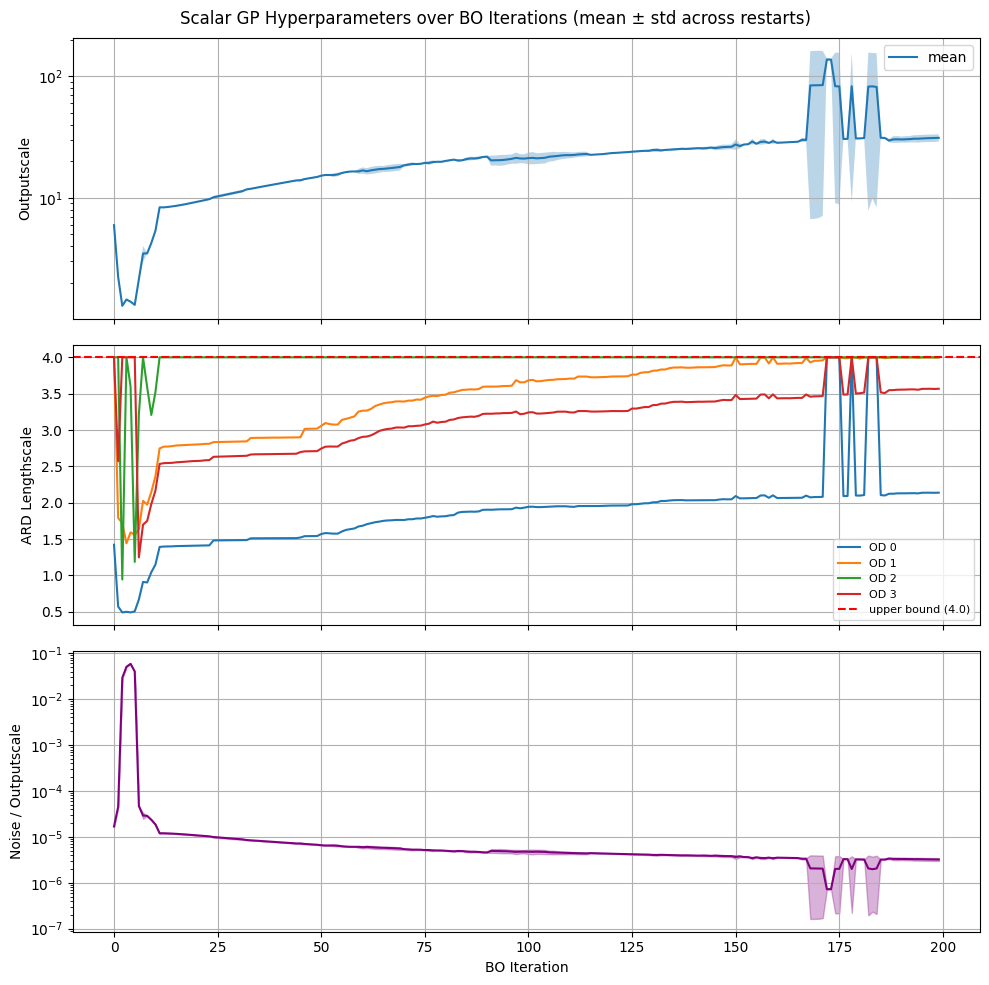

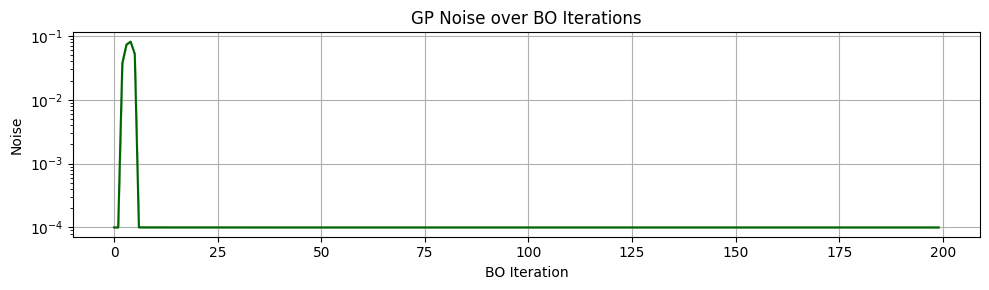

   hyperparameter early (1–10) mid (50–100) final (150–200)
      outputscale       2.6358      18.8433         44.7334
            noise     2.46e-02     1.00e-04        1.00e-04
lengthscale_dim_0       0.7239       1.7854          2.4011
lengthscale_dim_1       1.8251       3.4195          3.9710
lengthscale_dim_2       3.1261       4.0000          4.0000
lengthscale_dim_3       2.7415       3.0561          3.5746
 lengthscale_mean       2.1042       3.0652          3.4867


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = save_base / "results"

# Load all restarts
dfs = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    p = results_dir / f"restart_{r+1}_seed-{seed}" / "gp_diagnostics.csv"
    if p.exists():
        df = pd.read_csv(p)
        df["restart"] = r + 1
        dfs.append(df)

all_df = pd.concat(dfs, ignore_index=True)

# Mean ± std across restarts per iteration
grouped = all_df.groupby("iteration")
mean_df = grouped.mean(numeric_only=True)
std_df  = grouped.std(numeric_only=True)
iters   = mean_df.index
ls_cols = [c for c in mean_df.columns if c.startswith("lengthscale_dim_")]

# ── Plot 1: Outputscale, Lengthscales, Noise/Signal ──────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

axes[0].plot(iters, mean_df["outputscale"], label="mean")
axes[0].fill_between(iters,
    mean_df["outputscale"] - std_df["outputscale"],
    mean_df["outputscale"] + std_df["outputscale"], alpha=0.3)
axes[0].set_ylabel("Outputscale")
axes[0].set_yscale("log")
axes[0].legend(); axes[0].grid(True)

for col in ls_cols:
    axes[1].plot(iters, mean_df[col], label=col.replace("lengthscale_dim_", "OD "))
axes[1].axhline(4.0, color="red", linestyle="--", label="upper bound (4.0)")
axes[1].set_ylabel("ARD Lengthscale")
axes[1].legend(fontsize=8); axes[1].grid(True)

axes[2].plot(iters, mean_df["noise_signal_ratio"], color="purple")
axes[2].fill_between(iters,
    mean_df["noise_signal_ratio"] - std_df["noise_signal_ratio"],
    mean_df["noise_signal_ratio"] + std_df["noise_signal_ratio"], alpha=0.3, color="purple")
axes[2].set_ylabel("Noise / Outputscale")
axes[2].set_xlabel("BO Iteration")
axes[2].set_yscale("log"); axes[2].grid(True)

fig.suptitle("Scalar GP Hyperparameters over BO Iterations (mean ± std across restarts)")
plt.tight_layout()
plt.savefig(results_dir / "hyperparameters_over_iterations.pdf", bbox_inches="tight")
plt.show()

# ── Plot 2: Noise alone ───────────────────────────────────────────────────────
fig2, ax = plt.subplots(figsize=(10, 3))
ax.plot(iters, mean_df["noise"], color="darkgreen", label="mean noise")
ax.fill_between(iters,
    mean_df["noise"] - std_df["noise"],
    mean_df["noise"] + std_df["noise"], alpha=0.3, color="darkgreen")
ax.set_ylabel("Noise")
ax.set_xlabel("BO Iteration")
ax.set_yscale("log")
ax.grid(True)
ax.set_title("GP Noise over BO Iterations")
plt.tight_layout()
plt.savefig(results_dir / "noise_over_iterations.pdf", bbox_inches="tight")
plt.show()

# ── Table for paper ───────────────────────────────────────────────────────────
def phase_stats(df, lo, hi):
    sub = df[df["iteration"].between(lo, hi)]
    return sub.groupby("iteration").mean(numeric_only=True).mean()

early = phase_stats(all_df, 1, 10)
mid   = phase_stats(all_df, 50, 100)
final = phase_stats(all_df, 150, 200)

def fmt(val, col):
    if col == "noise":
        return f"{val:.2e}"
    return f"{val:.4f}"

cols = ["outputscale", "noise"] + ls_cols + ["lengthscale_mean"]
rows = []
for col in cols:
    rows.append({
        "hyperparameter":  col,
        "early (1–10)":    fmt(early[col], col),
        "mid (50–100)":    fmt(mid[col], col),
        "final (150–200)": fmt(final[col], col),
    })

table_df = pd.DataFrame(rows)
print(table_df.to_string(index=False))
table_df.to_csv(results_dir / "hyperparameter_table.csv", index=False)



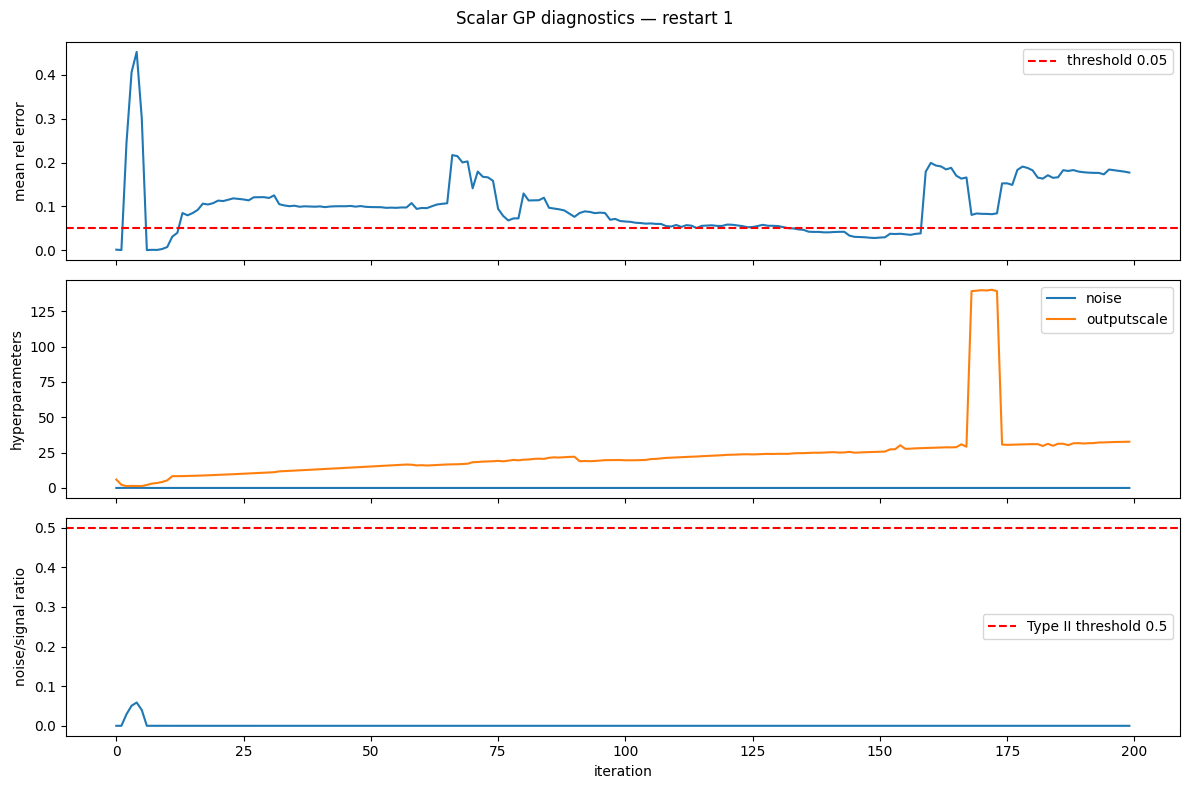

     iteration  mean_rel_error  noise_signal_ratio    best_S
0            0        0.001498        1.682104e-05  0.089236
1            1        0.000655        4.491536e-05  0.089236
2            2        0.244694        2.922976e-02  0.089236
3            3        0.405983        5.064744e-02  0.089236
4            4        0.452101        5.878844e-02  0.089236
5            5        0.301502        4.001642e-02  0.089236
6            6        0.000522        4.679802e-05  0.089236
7            7        0.001152        3.222876e-05  0.008764
8            8        0.000880        2.860011e-05  0.008764
9            9        0.002967        2.358054e-05  0.008764
10          10        0.007460        1.862113e-05  0.006392
11          11        0.031141        1.201566e-05  0.001846
12          12        0.040047        1.201660e-05  0.001144
13          13        0.084931        1.192997e-05  0.000175
14          14        0.079768        1.179931e-05  0.000175
15          15        0.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

diag = pd.read_csv(results_dir / "restart_11_seed-10042" / "gp_diagnostics.csv")

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(diag["iteration"], diag["mean_rel_error"])
axes[0].axhline(0.05, color="red", linestyle="--", label="threshold 0.05")
axes[0].set_ylabel("mean rel error")
axes[0].legend()

axes[1].plot(diag["iteration"], diag["noise"], label="noise")
axes[1].plot(diag["iteration"], diag["outputscale"], label="outputscale")
axes[1].set_ylabel("hyperparameters")
axes[1].legend()

axes[2].plot(diag["iteration"], diag["noise_signal_ratio"])
axes[2].axhline(0.5, color="red", linestyle="--", label="Type II threshold 0.5")
axes[2].set_ylabel("noise/signal ratio")
axes[2].set_xlabel("iteration")
axes[2].legend()

plt.suptitle("Scalar GP diagnostics — restart 1")
plt.tight_layout()
plt.show()

print(diag[["iteration", "mean_rel_error", "noise_signal_ratio", "best_S"]].to_string())


# 30 restart and 100 iterations. 

In [28]:
dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_X = train_X.to(device=device, dtype=dtype)
train_Y = train_Y.to(device=device, dtype=dtype)
N, d = train_X.shape
assert train_Y.shape == (N, 1), f"train_Y must be [N, 1], got {train_Y.shape}"

# bounds, bounds_norm, od_bound_start, od_bound_end, d — defined in Sobol/initial setup cell above
assert train_X.min() >= od_bound_start and train_X.max() <= od_bound_end, (
    f"train_X should be in [{od_bound_start}, {od_bound_end}]; got min={train_X.min():.2f}, max={train_X.max():.2f}. "
    "Use same bounds in the initial-data (Sobol) cell."
)

# Keep a copy of initial design for each restart
train_X_van_init = train_X.clone()
train_Y_van_init = train_Y.clone()

# BO and path settings
N_RESTARTS = 30
N_BO_ITERS = 100
kernel = "matern-2p5"
BO_FOLDER = "ScalarGP"
NOISE_LABEL = "noise_1e-4_1"  # Match gp_models.py Interval(1e-4, 1); separates runs by noise constraint

# Early stopping 
use_early_stop = config.get("EARLY_STOP_ENABLED", False)
EARLY_STOP_PATIENCE = config.get("EARLY_STOP_PATIENCE", 0) if use_early_stop else 0
EARLY_STOP_DELTA = config.get("EARLY_STOP_DELTA", 1e-6)
EARLY_STOP_MIN_ACQ = config.get("EARLY_STOP_MIN_ACQ", 0.0)

skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)

# Base dir for this noise setting: .../vanilla_bo/noise_1e-4_1/
save_base = Path(config["simulation_run_path"]) / BO_FOLDER / NOISE_LABEL
save_base.mkdir(parents=True, exist_ok=True)
results_dir = save_base / "results"
results_dir.mkdir(parents=True, exist_ok=True)

import xml.etree.ElementTree as _ET

def _load_vanilla_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                         best_S_init, gt_od_df, gt_edge_grouped,
                         grouped_edge_ids, device, dtype):
    train_X = train_X_init.clone()
    train_Y = train_Y_init.clone()
    best_S = best_S_init
    S_hist = [best_S_init]
    start_iter = 0
    for _it in range(n_bo_iters):
        loop_csv = sim_base / f"iter_{_it}" / "sim_loopOutputs.csv"
        od_xml   = sim_base / f"iter_{_it}" / "od.xml"
        if not loop_csv.exists() or not od_xml.exists():
            break
        tree = _ET.parse(str(od_xml))
        root = tree.getroot()
        rows = [el.attrib for el in root.iter("tazRelation")]
        _counts = pd.DataFrame(rows)["count"].astype(float).values
        _x = torch.tensor(_counts, device=device, dtype=dtype).view(1, -1)
        _df = pd.read_csv(str(loop_csv), sep=";")
        _df["interval_nVehContrib"] = _df["edge_arrived"] + _df["edge_left"]
        _df["interval_harmonicMeanSpeed"] = _df["edge_speed"]
        _df_agg = _df.groupby("edge_id", as_index=False).agg(
            interval_nVehContrib=("interval_nVehContrib", "sum"),
            interval_harmonicMeanSpeed=("interval_harmonicMeanSpeed", "mean"),
        )
        _grp = group_edge_dataframe(_df_agg)
        _loss = float(np.asarray(compute_squared_metric_all_edge(
            gt_edge_grouped, _grp, grouped_edge_ids
        )).flat[0])
        _y = torch.tensor([[_loss]], device=device, dtype=dtype)
        train_X = torch.cat([train_X, _x], dim=0)
        train_Y = torch.cat([train_Y, _y], dim=0)
        if _loss < best_S:
            best_S = _loss
        S_hist.append(best_S)
        start_iter = _it + 1
    return train_X, train_Y, best_S, S_hist, start_iter

vanilla_histories_raw = []

for r in range(N_RESTARTS):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    convergence_file = restart_dir / "convergence.csv"

    # Skip this restart if we already have convergence for it
    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        vanilla_histories_raw.append(S_history)
        print(f"\n VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(restart_seed)
    print(f"\n VANILLA BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")

    best_S_init = train_Y_van_init.min().item()
    sim_base = Path(save_base) / f"restart_{r+1}_seed-{restart_seed}"
    train_X_van, train_Y_van, best_S_raw, S_history_raw, start_iter = _load_vanilla_iters(
        sim_base, N_BO_ITERS,
        train_X_van_init, train_Y_van_init,
        best_S_init, gt_od_df, gt_edge_grouped,
        grouped_edge_ids, device, dtype,
    )
    best_checkpoint = best_S_raw
    no_improve_steps = 0

    if start_iter > 0:
        print(f"[RESUME] Loaded {start_iter} iters \u2192 resuming from iter {start_iter+1}/{N_BO_ITERS}, best S={best_S_raw:.6f}")
    else:
        print(f"[INIT] N={train_X_van.shape[0]}, best S (raw) = {best_S_raw:.6f}")
    if EARLY_STOP_PATIENCE > 0:
        print(f"  EARLY STOP: patience={EARLY_STOP_PATIENCE}, delta={EARLY_STOP_DELTA:.6e}")

    for it in range(start_iter, N_BO_ITERS):
        iter_t0 = time.time()  # Start timer for whole iteration (GP + EI + sim + parsing)

        # GP: fit on current (X, S) and get posterior
        train_X_norm = normalize(train_X_van, bounds=bounds)
        model = initialize_vanillabo_model(train_X_norm, train_Y_van, kernel=kernel).to(device=device, dtype=dtype)
        mll = ExactMarginalLogLikelihood(model.likelihood, model)
        fit_gpytorch_mll(mll)
        model.eval()

        # --- Acquisition: EI and optimize to get next point ---
        best_f_for_ei = train_Y_van.min()
        acquisition_function = ExpectedImprovement(model=model, best_f=best_f_for_ei, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            acq_function=acquisition_function,
            bounds=bounds_norm,
            q=1,
            num_restarts=config.get("BO_num_restarts", 10),
            raw_samples=config.get("BO_sample_shape", 128),
        )
        x_next_norm = x_next_norm.detach()
        x_next_real = unnormalize(x_next_norm, bounds).view(-1).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        # --- Prepare sim directory and OD file ---
        sim_dir = save_base / f"restart_{r+1}_seed-{restart_seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        new_od_xml = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)

        # --- Run SUMO simulation ---
        t0 = time.time()
        simulate_od(
            str(new_od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            seed=restart_seed + it,
        )
        print(f"[RUNTIME] Simulation took {time.time() - t0:.2f}s")

        # --- Parse outputs and compute scalar loss S(x_next) ---
        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )
        curr_loop_stats_grouped = group_edge_dataframe(curr_loop_stats)
        curr_loss = compute_squared_metric_all_edge(
            gt_edge_grouped, curr_loop_stats_grouped, grouped_edge_ids
        )
        curr_loss = float(np.asarray(curr_loss).flat[0])

        # --- Update best S and history ---
        if curr_loss < best_S_raw:
            best_S_raw = curr_loss
            print(f"[UPDATE] New BEST S = {best_S_raw:.6f}")
        else:
            print(f"[NO IMPROVEMENT] Best S remains {best_S_raw:.6f}")
        S_history_raw.append(best_S_raw)

        # --- Append (x_next, S(x_next)) to training set for next iteration ---
        train_X_van = torch.cat([
            train_X_van,
            torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1),
        ], dim=0)
        train_Y_van = torch.cat([
            train_Y_van,
            torch.tensor([[curr_loss]], device=device, dtype=dtype),
        ], dim=0)

        # --- Save per-iteration artifacts (optional) ---
        merged_data = pd.merge(
            gt_edge_grouped[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats[["edge_id", "interval_nVehContrib"]],
            on="edge_id",
            suffixes=("_gt", "_sim"),
        )
        merged_data.to_csv(sim_dir / "link_measure_compare.csv", index=False)
        (sim_dir / f"LOSS_{curr_loss:.6f}.txt").write_text(f"LOSS: {curr_loss:.6f}")
        if config.get("CLEANUP_INTERMEDIATE_FILES", False):
            try:
                if Path(sim_edge_out).exists():
                    Path(sim_edge_out).unlink()
            except Exception as e:
                print(f"[Warning] Cleanup: {e}")

        # --- Early stopping: no improvement for several iters ---
        if EARLY_STOP_PATIENCE > 0:
            delta = best_checkpoint - best_S_raw
            if delta >= EARLY_STOP_DELTA:
                best_checkpoint = best_S_raw
                no_improve_steps = 0
            else:
                no_improve_steps += 1
                if no_improve_steps >= EARLY_STOP_PATIENCE:
                    print(f"\nEARLY STOP: no improvement ≥ {EARLY_STOP_DELTA} for {EARLY_STOP_PATIENCE} iters. Best S: {best_S_raw:.6f}\n")
                    break
        if EARLY_STOP_MIN_ACQ > 0 and acq_val.item() < EARLY_STOP_MIN_ACQ:
            print(f"\nEARLY STOP: EI < {EARLY_STOP_MIN_ACQ}. Best S: {best_S_raw:.6f}\n")
            break

        # --- Log iteration: loss, best S, EI, total iteration time ---
        iter_elapsed = time.time() - iter_t0
        print(f"[BO iter {it+1}/{N_BO_ITERS}] S(x_next)={curr_loss:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}, time={iter_elapsed:.2f}s")

    vanilla_histories_raw.append(S_history_raw)
    print(f"\n[RESTART {r+1} COMPLETE] Final best S = {best_S_raw:.6f}")

    # Save immediately so skip_if_saved works on re-run
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history_raw)), "best_S": S_history_raw}).to_csv(
        convergence_file, index=False
    )
    print(f"\u2713 Convergence saved: {convergence_file}")

# --- Aggregate across restarts (pad to same length) ---
max_len = max(len(h) for h in vanilla_histories_raw)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(vanilla_histories_raw):
    padded[i, :len(h)] = h
mean_curve = np.nanmean(padded, axis=0)
std_curve = np.nanstd(padded, axis=0)
best_S_per_restart = [h[-1] for h in vanilla_histories_raw]
overall_best = min(best_S_per_restart)

print("VANILLA BO COMPLETE")
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)

# --- Write per-restart convergence CSV ---
for r, S_history in enumerate(vanilla_histories_raw):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    restart_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"iteration": range(len(S_history)), "best_S": S_history}).to_csv(
        restart_dir / "convergence.csv", index=False
    )

# --- Write mean/std curve and summary ---
pd.DataFrame({
    "iteration": range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std": std_curve,
}).to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean": float(np.mean(best_S_per_restart)),
        "best_S_std": float(np.std(best_S_per_restart)),
        "overall_best_S": float(overall_best),
        "n_restarts": N_RESTARTS,
        "n_bo_iters": N_BO_ITERS,
        "n_initial": train_X.shape[0],
        "kernel": kernel,
        "metric": "squared",
        "od_bound_start": od_bound_start,
        "od_bound_end": od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({
    f"restart_{r+1}": vanilla_histories_raw[r] + [np.nan] * (max_len - len(vanilla_histories_raw[r]))
    for r in range(N_RESTARTS)
})
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

print(f"\n✓ Saved: {results_dir}")
print(f"  - restart_X_seed-Y/convergence.csv")
print(f"  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")


 VANILLA BO RESTART 1/30 (seed=42) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000015

 VANILLA BO RESTART 2/30 (seed=1042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000027

 VANILLA BO RESTART 3/30 (seed=2042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000006

 VANILLA BO RESTART 4/30 (seed=3042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000009

 VANILLA BO RESTART 5/30 (seed=4042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000003

 VANILLA BO RESTART 6/30 (seed=5042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000067

 VANILLA BO RESTART 7/30 (seed=6042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000078

 VANILLA BO RESTART 8/30 (seed=7042) — SKIPPED (already saved) #########
  Loaded 101 iterations, best S = 0.000015

 VANILLA BO RESTART 9/30 (seed=8042) — SKIPPED (already saved) ##

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_21_seed-20042/iter_0/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_21_seed-20042/iter_0/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (4ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (2ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_b

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_21_seed-20042/iter_1/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_21_seed-20042/iter_1/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_b

...

Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_30_seed-29042/iter_97/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_30_seed-29042/iter_97/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_30_seed-29042/iter_98/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_30_seed-29042/iter_98/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_30_seed-29042/iter_99/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/ScalarGP/noise_1e-4_1/restart_30_seed-29042/iter_99/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration

In [19]:
_dummy = initialize_vanillabo_model(
    normalize(train_X_van_init[:2], bounds=bounds),
    train_Y_van_init[:2],
    kernel=kernel,
)
li = _dummy.likelihood
# List attributes that might hold the constraint
attrs = [a for a in dir(li) if "constraint" in a.lower() or ("raw" in a.lower() and "noise" in a.lower())]
print("Likelihood attributes (constraint/raw/noise):", attrs)
for a in attrs:
    try:
        val = getattr(li, a)
        if val is not None:
            print(f"  {a}: {val}")
    except Exception as e:
        print(f"  {a}: <error {e}>")
# Also try parameter constraint (GPyTorch often attaches constraint to the parameter)
for name, param in li.named_parameters():
    if hasattr(param, "constraint") and param.constraint is not None:
        print(f"  param {name}.constraint: {param.constraint}")

Likelihood attributes (constraint/raw/noise): ['_constraints', 'constraint_for_parameter_name', 'constraints', 'named_constraints', 'named_parameters_and_constraints', 'raw_noise', 'register_constraint']
  _constraints: {}
  constraint_for_parameter_name: <bound method Module.constraint_for_parameter_name of GaussianLikelihood(
  (noise_covar): HomoskedasticNoise(
    (raw_noise_constraint): Interval(1.000E-04, 1.000E+00)
  )
)>
  constraints: <bound method Module.constraints of GaussianLikelihood(
  (noise_covar): HomoskedasticNoise(
    (raw_noise_constraint): Interval(1.000E-04, 1.000E+00)
  )
)>
  named_constraints: <bound method Module.named_constraints of GaussianLikelihood(
  (noise_covar): HomoskedasticNoise(
    (raw_noise_constraint): Interval(1.000E-04, 1.000E+00)
  )
)>
  named_parameters_and_constraints: <bound method Module.named_parameters_and_constraints of GaussianLikelihood(
  (noise_covar): HomoskedasticNoise(
    (raw_noise_constraint): Interval(1.000E-04, 1.000E+00

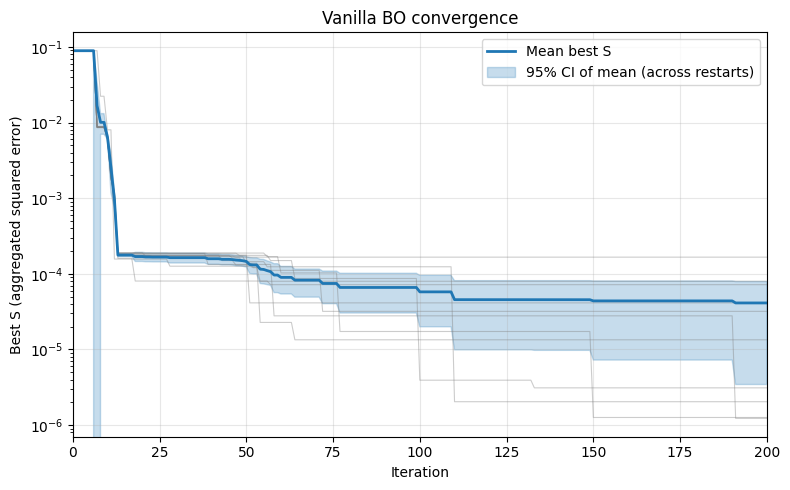

In [24]:
n_restarts = len(vanilla_histories_raw)
min_len = min(len(h) for h in vanilla_histories_raw)
aligned_histories = np.array([h[:min_len] for h in vanilla_histories_raw])

iters = np.arange(min_len)

# Mean and standard deviation across restarts
mean_curve = aligned_histories.mean(axis=0)

if n_restarts > 1:
    std_curve = aligned_histories.std(axis=0, ddof=1) 
else:
    std_curve = np.zeros_like(mean_curve)


if n_restarts > 1:
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1)
    ci_half = t_critical * (std_curve / np.sqrt(n_restarts))
else:
    ci_half = np.zeros_like(mean_curve)




fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Individual restart curves
for h in vanilla_histories_raw:
    ax.plot(
        np.arange(min(len(h), min_len)),
        h[:min_len],
        color="gray",
        alpha=0.4,
        linewidth=0.8,
    )

# Mean curve
ax.plot(
    iters,
    mean_curve,
    color="C0",
    linewidth=2,
    label="Mean best S",
)

# 95% CI of the mean
ax.fill_between(
    iters,
    mean_curve - ci_half,
    mean_curve + ci_half,
    color="C0",
    alpha=0.25,
    label="95% CI of mean (across restarts)",
)


ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (aggregated squared error)")
ax.set_title("Vanilla BO convergence")
ax.set_yscale("log")
ax.set_xlim(0, min_len - 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


# LOO-CV + Calibration validation | Vanilla GP

Fitting Vanilla GP on N=210 points for LOO validation...
Vanilla GP fitted


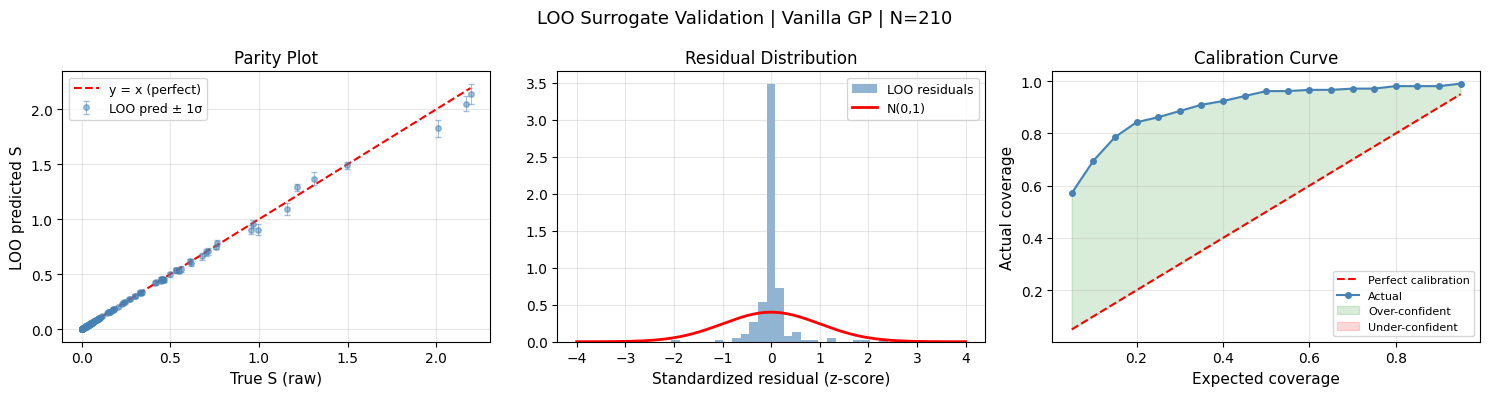


=== LOO-CV Results (Vanilla GP) ===
  RMSE:          0.019012
  MAE:           0.004583
  Within 1σ:     96.7%  (ideal: 68%)
  Within 2σ:     99.0%  (ideal: 95%)
  ⚠ Underconfident: uncertainty too wide → EI will over-explore


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy import stats as _stats
from botorch.utils.transforms import normalize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood

# ─── Setup: use final training data from vanilla BO (last restart in scope) ─
# train_X_van [N, d], train_Y_van [N, 1], bounds, kernel, device, dtype in scope
N = train_X_van.shape[0]
train_X_norm_val = normalize(train_X_van, bounds=bounds)

# ─── Fit scalar GP on all training data ─────────────────────────────────────
print(f"Fitting Vanilla GP on N={N} points for LOO validation...")
van_val = initialize_vanillabo_model(train_X_norm_val, train_Y_van, kernel=kernel)
mll_van = ExactMarginalLogLikelihood(van_val.likelihood, van_val)
van_val = van_val.to(device=device, dtype=dtype)
mll_van = mll_van.to(device=device, dtype=dtype)
van_val.train(); mll_van.train()
fit_gpytorch_mll(mll_van)
van_val.eval()
print("Vanilla GP fitted")

# ─── Efficient LOO via C^-1 ──────────────────────────────────────────────────
# SingleTaskGP with Standardize: internal targets are standardized.
# LOO formula:  loo_mean_i = y_i - alpha_i / C^-1_ii
#               loo_std_i  = 1 / sqrt(C^-1_ii)
# where C = K + noise * I  (all in standardized space)
with torch.no_grad():
    K_data = van_val.covar_module(train_X_norm_val).evaluate()   # [N, N]
    noise  = van_val.likelihood.noise.squeeze()                   # scalar

    # Standardization params stored by BoTorch Standardize transform
    y_mean_tf = van_val.outcome_transform.means.squeeze()         # scalar
    y_std_tf  = van_val.outcome_transform.stdvs.squeeze()         # scalar
    y_std_vec = (train_Y_van.squeeze(-1) - y_mean_tf) / y_std_tf # [N]

    C      = K_data + noise * torch.eye(N, dtype=dtype, device=device)
    C_inv  = torch.linalg.inv(C)
    alpha  = C_inv @ y_std_vec
    C_diag = C_inv.diagonal().clamp_min(1e-8)

    # LOO in standardized space, then de-standardize
    loo_mu_std  = y_std_vec - alpha / C_diag                      # [N]
    loo_std_std = (1.0 / C_diag).clamp_min(0).sqrt()             # [N]

    loo_means_np = (loo_mu_std * y_std_tf + y_mean_tf).cpu().numpy()
    loo_stds_np  = (loo_std_std * y_std_tf.abs()).cpu().numpy()
    train_S_np   = train_Y_van.squeeze(-1).cpu().numpy()

residuals = (train_S_np - loo_means_np) / loo_stds_np

# ─── Plots ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(f"LOO Surrogate Validation | Vanilla GP | N={N}", fontsize=13)

# 1. Parity plot
ax = axes[0]
mn = min(train_S_np.min(), loo_means_np.min())
mx = max(train_S_np.max(), loo_means_np.max())
ax.errorbar(train_S_np, loo_means_np, yerr=loo_stds_np,
            fmt='o', ms=4, alpha=0.5, color='steelblue',
            ecolor='steelblue', elinewidth=0.7, capsize=2, label='LOO pred \u00b1 1\u03c3')
ax.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='y = x (perfect)')
ax.set_xlabel('True S (raw)', fontsize=11)
ax.set_ylabel('LOO predicted S', fontsize=11)
ax.set_title('Parity Plot')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# 2. Standardized residuals histogram
ax = axes[1]
ax.hist(residuals, bins=25, density=True, alpha=0.6, color='steelblue', label='LOO residuals')
x_r = np.linspace(-4, 4, 200)
ax.plot(x_r, np.exp(-0.5 * x_r**2) / np.sqrt(2 * np.pi), 'r-', lw=2, label='N(0,1)')
ax.set_xlabel('Standardized residual (z-score)', fontsize=11)
ax.set_title('Residual Distribution')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# 3. Calibration curve
ax = axes[2]
levels = np.linspace(0.05, 0.95, 19)
coverage = [np.mean(np.abs(residuals) <= _stats.norm.ppf((1 + lv) / 2)) for lv in levels]
above = np.array(coverage) >= levels
ax.plot(levels, levels, 'r--', lw=1.5, label='Perfect calibration')
ax.plot(levels, coverage, 'o-', color='steelblue', ms=4, label='Actual')
ax.fill_between(levels, levels, coverage, where=above, alpha=0.15, color='green', label='Over-confident')
ax.fill_between(levels, levels, coverage, where=~above, alpha=0.15, color='red', label='Under-confident')
ax.set_xlabel('Expected coverage', fontsize=11)
ax.set_ylabel('Actual coverage', fontsize=11)
ax.set_title('Calibration Curve')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ─── Summary stats ────────────────────────────────────────────────────────────
rmse = np.sqrt(np.mean((train_S_np - loo_means_np) ** 2))
mae  = np.mean(np.abs(train_S_np - loo_means_np))
p68  = np.mean(np.abs(residuals) <= 1.00) * 100
p95  = np.mean(np.abs(residuals) <= 1.96) * 100
print("\n=== LOO-CV Results (Vanilla GP) ===")
print(f"  RMSE:          {rmse:.6f}")
print(f"  MAE:           {mae:.6f}")
print(f"  Within 1\u03c3:     {p68:.1f}%  (ideal: 68%)")
print(f"  Within 2\u03c3:     {p95:.1f}%  (ideal: 95%)")
if p68 < 50:
    print("  \u26a0 Overconfident: uncertainty too narrow \u2192 EI may over-exploit")
elif p68 > 85:
    print("  \u26a0 Underconfident: uncertainty too wide \u2192 EI will over-explore")
else:
    print("  \u2713 Calibration looks reasonable")


In [19]:
noise_val = model.likelihood.noise.item()
print(f"Learned noise (raw scale): {noise_val:.6f}")

# Also check outputscale and lengthscale
print(f"Outputscale: {model.covar_module.outputscale.item():.6f}")
print(f"Lengthscale: {model.covar_module.base_kernel.lengthscale.detach().numpy()}")

Learned noise (raw scale): 0.000100
Outputscale: 29.667593
Lengthscale: [[2.13833144 3.99915031 3.9999292  3.56754606]]


In [20]:
print(f"S min:   {train_Y_van.min().item():.6f}")
print(f"S max:   {train_Y_van.max().item():.6f}")
print(f"S mean:  {train_Y_van.mean().item():.6f}")
print(f"S range: {(train_Y_van.max() - train_Y_van.min()).item():.6f}")
print(f"RMSE as % of range: {0.019012 / (train_Y_van.max() - train_Y_van.min()).item() * 100:.1f}%")


S min:   0.000008
S max:   2.194448
S mean:  0.171544
S range: 2.194440
RMSE as % of range: 0.9%


# ind gp squared metric 

one gp per edge, is fitted on error


So the notebook is doing ind GP with grouped edges and uniform weights 

In [21]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import torch
import json
import xml.etree.ElementTree as _ET

from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.utils.transforms import normalize, unnormalize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood

from src.utils.seed import set_seed
from src.models.gp_models import (
    initialize_independent_gp_models_with_modellist,
    make_linear_aggregation_model_from_error_gps,
    extract_independent_gp_hyperparameters,
)

dtype = torch.double
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

od_bound_start = config.get("od_bound_start", 1)
od_bound_end = config.get("od_bound_end", 2000)

N_RESTARTS = 11
N_BO_ITERS = 200
kernel = "matern-2p5"
BO_FOLDER = "indgp_bo_squared_grouped"
NOISE_LABEL = "noise_1e-4_1"

save_base = Path(config["simulation_run_path"]) / BO_FOLDER / NOISE_LABEL / "NEW"
save_base.mkdir(parents=True, exist_ok=True)
results_dir = save_base / "results"
results_dir.mkdir(parents=True, exist_ok=True)
initial_design_path = results_dir / "initial_design_squared.npz"

if initial_design_path.exists():
    data = np.load(initial_design_path)
    train_X_ind_init = torch.tensor(data["train_X"], dtype=dtype, device=device)
    train_Y_ind_init = torch.tensor(data["train_Y"], dtype=dtype, device=device)
    print(f"[INIT] Loaded initial design from {initial_design_path} (N={train_X_ind_init.shape[0]}, d={train_X_ind_init.shape[1]})")
else:
    train_X_ind_init = torch.tensor(np.array(train_X_list), dtype=dtype, device=device)
    train_Y_ind_init = torch.tensor(np.array(train_E_list), dtype=dtype, device=device)
    np.savez(
        initial_design_path,
        train_X=train_X_ind_init.cpu().numpy(),
        train_Y=train_Y_ind_init.cpu().numpy(),
    )
    print(f"[INIT] Saved initial design to {initial_design_path} (N={train_X_ind_init.shape[0]}, d={train_X_ind_init.shape[1]})")

N, d = train_X_ind_init.shape
L = train_Y_ind_init.shape[1]
assert len(edge_ids) == L, f"edge_ids ({len(edge_ids)}) must match L ({L})"

weights_t = torch.tensor(weights_np, dtype=dtype, device=device)

bounds = torch.stack([
    torch.full((d,), od_bound_start, dtype=dtype, device=device),
    torch.full((d,), od_bound_end, dtype=dtype, device=device),
])
bounds_norm = torch.stack([
    torch.zeros(d, dtype=dtype, device=device),
    torch.ones(d, dtype=dtype, device=device),
])

use_early_stop = config.get("EARLY_STOP_ENABLED", False)
EARLY_STOP_PATIENCE = config.get("EARLY_STOP_PATIENCE", 0) if use_early_stop else 0
EARLY_STOP_DELTA = config.get("EARLY_STOP_DELTA", 1e-6)
EARLY_STOP_MIN_ACQ = config.get("EARLY_STOP_MIN_ACQ", 0.0)
skip_if_saved = config.get("SKIP_RESTART_IF_SAVED", True)


def _load_indgp_iters(sim_base, n_bo_iters, train_X_init, train_Y_init,
                      best_S_init, edge_ids, weights_np, device, dtype):
    train_X = train_X_init.clone()
    train_Y = train_Y_init.clone()
    best_S = best_S_init
    S_hist = [best_S_init]
    start_iter = 0

    for _it in range(n_bo_iters):
        od_xml = sim_base / f"iter_{_it}" / "od.xml"
        compare_csv = sim_base / f"iter_{_it}" / "link_measure_compare.csv"
        if not od_xml.exists() or not compare_csv.exists():
            break

        tree = _ET.parse(str(od_xml))
        rows = [el.attrib for el in tree.getroot().iter("tazRelation")]
        _counts = pd.DataFrame(rows)["count"].astype(float).values
        _x = torch.tensor(_counts, device=device, dtype=dtype).view(1, -1)

        _df = pd.read_csv(str(compare_csv)).set_index("edge_id")
        per_edge_errors = []
        for eid in edge_ids:
            if eid in _df.index:
                gt_val = float(_df.loc[eid, "interval_nVehContrib_gt"])
                sim_val = float(_df.loc[eid, "interval_nVehContrib_sim"])
                if gt_val > 0:
                    per_edge_errors.append(((sim_val - gt_val) / gt_val) ** 2)
                else:
                    per_edge_errors.append(np.nan)
            else:
                per_edge_errors.append(np.nan)

        _y = torch.tensor(per_edge_errors, device=device, dtype=dtype).view(1, -1)
        _loss = float((np.asarray(per_edge_errors) * weights_np).sum())
        if np.isnan(_loss):
            _loss = float("inf")

        train_X = torch.cat([train_X, _x], dim=0)
        train_Y = torch.cat([train_Y, _y], dim=0)
        if _loss < best_S:
            best_S = _loss
        S_hist.append(best_S)
        start_iter = _it + 1

    return train_X, train_Y, best_S, S_hist, start_iter


def _log_hyperparameters(model_list_gp, weights_t, edge_ids, iteration, hp_log_path):
    agg = make_linear_aggregation_model_from_error_gps(model_list_gp, weights=weights_t)
    hp = extract_independent_gp_hyperparameters(agg, edge_ids=edge_ids)
    rows = []
    for row in hp["per_edge"]:
        ls = row["lengthscale"]
        ls_list = ls if isinstance(ls, list) else [float(ls)]
        entry = {
            "iteration":        iteration,
            "edge_id":          row["edge_id"],
            "outputscale":      row["outputscale"],
            "noise":            row["noise"],
            "lengthscale_mean": float(np.mean(ls_list)),
            "lengthscale_min":  float(np.min(ls_list)),
            "lengthscale_max":  float(np.max(ls_list)),
            **{f"lengthscale_dim_{i}": float(v) for i, v in enumerate(ls_list)},
        }
        rows.append(entry)
    df = pd.DataFrame(rows)
    df.to_csv(hp_log_path, mode="a", header=not hp_log_path.exists(), index=False)



indgp_histories_raw = []

for r in range(N_RESTARTS):
    restart_seed = 42 + r * 1000
    restart_dir = results_dir / f"restart_{r+1}_seed-{restart_seed}"
    convergence_file = restart_dir / "convergence.csv"
    hp_log_path = restart_dir / "hyperparameters_per_iteration.csv"

    if skip_if_saved and convergence_file.exists():
        S_history = pd.read_csv(convergence_file)["best_S"].tolist()
        indgp_histories_raw.append(S_history)
        print(f"\n######### IND-GP BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) — SKIPPED (already saved) #########")
        print(f"  Loaded {len(S_history)} iterations, best S = {S_history[-1]:.6f}")
        continue

    set_seed(restart_seed)
    print(f"\n######### IND-GP BO RESTART {r+1}/{N_RESTARTS} (seed={restart_seed}) #########")

    best_S_init = (train_Y_ind_init * weights_t).sum(dim=1).nan_to_num(float("inf")).min().item()
    sim_base = save_base / f"restart_{r+1}_seed-{restart_seed}"
    train_X_ind, train_Y_ind, best_S_raw, S_history_raw, start_iter = _load_indgp_iters(
        sim_base, N_BO_ITERS,
        train_X_ind_init, train_Y_ind_init,
        best_S_init, edge_ids, weights_np,
        device, dtype,
    )
    no_improve_steps = 0
    best_checkpoint = best_S_raw

    restart_dir.mkdir(parents=True, exist_ok=True)
    # clear any previous partial hp log if resuming from scratch
    if start_iter == 0 and hp_log_path.exists():
        hp_log_path.unlink()

    if start_iter > 0:
        print(f"[RESUME] Loaded {start_iter} iters → resuming from iter {start_iter+1}/{N_BO_ITERS}, best S={best_S_raw:.6f}")
    else:
        print(f"[INIT] N={train_X_ind.shape[0]}, best S (raw) = {best_S_raw:.6f}")
    if EARLY_STOP_PATIENCE > 0:
        print(f"  EARLY STOP: patience={EARLY_STOP_PATIENCE}, delta={EARLY_STOP_DELTA:.6e}")

    for it in range(start_iter, N_BO_ITERS):
        train_X_norm = normalize(train_X_ind, bounds=bounds)
        model_list_gp_errors, mlls = initialize_independent_gp_models_with_modellist(
            train_X_norm, train_Y_ind, kernel=kernel
        )

        for i, mll in enumerate(mlls):
            try:
                fit_gpytorch_mll(mll)
            except Exception as e:
                print(f"[WARNING] Edge {edge_ids[i]} fit warning: {str(e)[:80]}")

        # --- log hyperparameters for this iteration ---
        _log_hyperparameters(model_list_gp_errors, weights_t, edge_ids, it, hp_log_path)

        agg_model = make_linear_aggregation_model_from_error_gps(
            model_list_gp_errors, weights=weights_t
        )
        agg_model.eval()

        EI = ExpectedImprovement(model=agg_model, best_f=best_S_raw, maximize=False)
        x_next_norm, acq_val = optimize_acqf(
            acq_function=EI,
            bounds=bounds_norm,
            q=1,
            num_restarts=config.get("BO_num_restarts", 10),
            raw_samples=config.get("BO_sample_shape", 128),
        )
        x_next_norm = x_next_norm.detach()
        x_next_real = unnormalize(x_next_norm, bounds=bounds).squeeze(0).cpu().numpy()
        x_next_real = np.clip(x_next_real, od_bound_start, od_bound_end)

        sim_dir = save_base / f"restart_{r+1}_seed-{restart_seed}" / f"iter_{it}"
        sim_dir.mkdir(parents=True, exist_ok=True)
        new_od_xml = sim_dir / "od.xml"
        prefix_output = sim_dir / "sim"

        base_od = gt_od_df.copy()
        base_od["count"] = [round(v, 1) for v in x_next_real]
        base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
        create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)

        t0 = time.time()
        simulate_od(
            str(new_od_xml), str(prefix_output), base_path,
            config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
            routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
        )
        print(f"[RUNTIME] Simulation took {time.time() - t0:.2f}s")

        sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
        curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
            base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
        )
        curr_loop_stats_grouped = group_edge_dataframe(curr_loop_stats)
        per_edge_errors = compute_squared_metric_per_edge(
            df_true=gt_edge_grouped,
            df_simulated=curr_loop_stats_grouped,
            edge_ids=edge_ids,
        )
        curr_loss = float((np.asarray(per_edge_errors) * weights_np).sum())
        if np.isnan(curr_loss):
            curr_loss = float("inf")

        if curr_loss < best_S_raw:
            best_S_raw = curr_loss
            print(f"[UPDATE] New BEST S = {best_S_raw:.6f}")
        else:
            print(f"[NO IMPROVEMENT] Best S remains {best_S_raw:.6f}")
        S_history_raw.append(best_S_raw)

        train_X_ind = torch.cat([
            train_X_ind,
            torch.tensor(x_next_real, device=device, dtype=dtype).view(1, -1),
        ], dim=0)
        train_Y_ind = torch.cat([
            train_Y_ind,
            torch.tensor(per_edge_errors, device=device, dtype=dtype).view(1, -1),
        ], dim=0)

        merged_data = pd.merge(
            gt_edge_grouped[["edge_id", "interval_nVehContrib"]],
            curr_loop_stats_grouped[["edge_id", "interval_nVehContrib"]],
            on="edge_id",
            suffixes=("_gt", "_sim"),
        )
        merged_data.to_csv(sim_dir / "link_measure_compare.csv", index=False)
        (sim_dir / f"LOSS_{curr_loss:.6f}.txt").write_text(f"LOSS: {curr_loss:.6f}")

        if config.get("CLEANUP_INTERMEDIATE_FILES", False):
            try:
                if Path(sim_edge_out).exists():
                    Path(sim_edge_out).unlink()
            except Exception as e:
                print(f"[Warning] Cleanup: {e}")

        if EARLY_STOP_PATIENCE > 0:
            delta = best_checkpoint - best_S_raw
            if delta >= EARLY_STOP_DELTA:
                best_checkpoint = best_S_raw
                no_improve_steps = 0
            else:
                no_improve_steps += 1
                if no_improve_steps >= EARLY_STOP_PATIENCE:
                    print(f"\nEARLY STOP: no improvement ≥ {EARLY_STOP_DELTA} for {EARLY_STOP_PATIENCE} iters. Best S: {best_S_raw:.6f}\n")
                    break
        if EARLY_STOP_MIN_ACQ > 0 and acq_val.item() < EARLY_STOP_MIN_ACQ:
            print(f"\nEARLY STOP: EI < {EARLY_STOP_MIN_ACQ}. Best S: {best_S_raw:.6f}\n")
            break

        print(f"[BO iter {it+1}/{N_BO_ITERS}] S(x_next)={curr_loss:.6f}, best S={best_S_raw:.6f}, EI={acq_val.item():.6f}")

    indgp_histories_raw.append(S_history_raw)
    print(f"\n[RESTART {r+1} COMPLETE] Final best S = {best_S_raw:.6f}")

    pd.DataFrame({"iteration": range(len(S_history_raw)), "best_S": S_history_raw}).to_csv(
        restart_dir / "convergence.csv", index=False
    )
    print(f"✓ Convergence saved: {convergence_file}")
    print(f"✓ Hyperparameters per iteration saved: {hp_log_path}")

    if r == N_RESTARTS - 1:
        train_X_norm = normalize(train_X_ind, bounds=bounds)
        model_list_gp_errors, mlls = initialize_independent_gp_models_with_modellist(
            train_X_norm, train_Y_ind, kernel=kernel
        )
        for i, mll in enumerate(mlls):
            try:
                fit_gpytorch_mll(mll)
            except Exception as e:
                print(f"[WARNING] Edge {edge_ids[i]} fit warning: {str(e)[:80]}")
        agg_model = make_linear_aggregation_model_from_error_gps(model_list_gp_errors, weights=weights_t)
        hp = extract_independent_gp_hyperparameters(agg_model, edge_ids=edge_ids)
        def _to_serializable(obj):
            if isinstance(obj, dict):
                return {k: _to_serializable(v) for k, v in obj.items()}
            if isinstance(obj, list):
                return [_to_serializable(x) for x in obj]
            if hasattr(obj, "item"):
                return float(obj)
            if isinstance(obj, (int, float, str, bool, type(None))):
                return obj
            return obj
        with open(results_dir / "hyperparameters_last_iteration.json", "w") as f:
            json.dump(_to_serializable(hp), f, indent=2)
        print(f"  Saved hyperparameters_last_iteration.json")
        if hp.get("per_edge"):
            pd.DataFrame(hp["per_edge"]).to_csv(results_dir / "hyperparameters_per_edge.csv", index=False)
            print(f"  Saved hyperparameters_per_edge.csv")

        S_all = (train_Y_ind * weights_t).sum(dim=1).cpu().numpy()
        best_idx = int(np.argmin(S_all))
        best_od = train_X_ind[best_idx].cpu().numpy()
        best_S = float(S_all[best_idx])
        print(f"  Best eval index: {best_idx}, S = {best_S:.6f}")
        gt_od_vals = gt_od_df["count"].astype(float).to_numpy()
        gt_flows = gt_edge_grouped.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
        sim_edge_counts_best = None
        try:
            sim_dir_best = restart_dir / "best_eval"
            sim_dir_best.mkdir(parents=True, exist_ok=True)
            new_od_xml = sim_dir_best / "od.xml"
            prefix_output = sim_dir_best / "sim"
            base_od = gt_od_df.copy()
            base_od["count"] = [round(v, 1) for v in best_od]
            base_od = base_od.rename(columns={"fromTaz": "from", "toTaz": "to"})
            create_taz_xml(str(new_od_xml), base_od, config["od_duration_sec"], base_path)
            simulate_od(
                str(new_od_xml), str(prefix_output), base_path,
                config["net_xml"], config["taz2edge_xml"], config["additional_xml"],
                routes_df, config["sim_end_time"], config["TRIPS2ODS_OUT_STR"],
            )
            sim_edge_out = f"{prefix_output}_{config['EDGE_OUT_STR']}"
            curr_loop_stats, _, _ = parse_loop_data_xml_to_pandas(
                base_path, sim_edge_out, str(prefix_output), str(config["SUMO_PATH"]),
            )
            curr_loop_stats_grouped_best = group_edge_dataframe(curr_loop_stats)
            sim_edge_counts_best = curr_loop_stats_grouped_best.set_index("edge_id").loc[edge_ids, "interval_nVehContrib"].values.astype(float)
            print("  ✓ Simulated best-iteration run for cv_data")
        except Exception as e:
            print(f"  [Skip] Best-eval sim failed: {e}; cv_data saved without sim_edge_counts.")
        save_kw = dict(
            X=train_X_ind.cpu().numpy(),
            Y=train_Y_ind.cpu().numpy(),
            edge_ids=np.array(edge_ids),
            weights=weights_np,
            gt_od=gt_od_vals,
            gt_edge_counts=gt_flows,
        )
        if sim_edge_counts_best is not None:
            save_kw["sim_edge_counts"] = sim_edge_counts_best
        np.savez(restart_dir / "cv_data.npz", **save_kw)
        print("  ✓ Saved cv_data.npz")

# aggregate across restarts
max_len = max(len(h) for h in indgp_histories_raw)
padded = np.full((N_RESTARTS, max_len), np.nan)
for i, h in enumerate(indgp_histories_raw):
    padded[i, :len(h)] = h
mean_curve = np.nanmean(padded, axis=0)
std_curve = np.nanstd(padded, axis=0)
best_S_per_restart = [h[-1] for h in indgp_histories_raw]
overall_best = min(best_S_per_restart)

print("\n" + "=" * 60)
print("IND-GP BO COMPLETE")
print("=" * 60)
print(f"Restarts: {N_RESTARTS}, Iterations per restart: {N_BO_ITERS}")
print(f"Best S per restart: {[f'{s:.6f}' for s in best_S_per_restart]}")
print(f"Mean best S: {np.mean(best_S_per_restart):.6f} ± {np.std(best_S_per_restart):.6f}")
print(f"Overall best S: {overall_best:.6f}")
print("=" * 60)

pd.DataFrame({
    "iteration": range(len(mean_curve)),
    "best_S_mean": mean_curve,
    "best_S_std": std_curve,
}).to_csv(results_dir / "convergence_mean_std.csv", index=False)

with open(results_dir / "summary.json", "w") as f:
    json.dump({
        "best_S_per_restart": best_S_per_restart,
        "best_S_mean": float(np.mean(best_S_per_restart)),
        "best_S_std": float(np.std(best_S_per_restart)),
        "overall_best_S": float(overall_best),
        "n_restarts": N_RESTARTS,
        "n_bo_iters": N_BO_ITERS,
        "n_initial": train_X_ind_init.shape[0],
        "kernel": kernel,
        "metric": "squared_per_edge",
        "od_bound_start": od_bound_start,
        "od_bound_end": od_bound_end,
    }, f, indent=2)

df_histories = pd.DataFrame({
    f"restart_{r+1}": indgp_histories_raw[r] + [np.nan] * (max_len - len(indgp_histories_raw[r]))
    for r in range(N_RESTARTS)
})
df_histories["mean"] = mean_curve
df_histories.index.name = "iteration"
df_histories.to_csv(results_dir / "all_restarts_convergence.csv")

print(f"\n✓ Saved: {results_dir}")
print(f"  - restart_X_seed-Y/convergence.csv")
print(f"  - restart_X_seed-Y/hyperparameters_per_iteration.csv  ← NEW")
print(f"  - convergence_mean_std.csv, summary.json, all_restarts_convergence.csv")




[INIT] Loaded initial design from output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/results/initial_design_squared.npz (N=10, d=4)

######### IND-GP BO RESTART 1/11 (seed=42) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000000

######### IND-GP BO RESTART 2/11 (seed=1042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000000

######### IND-GP BO RESTART 3/11 (seed=2042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000014

######### IND-GP BO RESTART 4/11 (seed=3042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000090

######### IND-GP BO RESTART 5/11 (seed=4042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000021

######### IND-GP BO RESTART 6/11 (seed=5042) — SKIPPED (already saved) #########
  Loaded 201 iterations, best S = 0.000001

######### IND-GP BO RESTART 7/11 (seed=6042) — SKIPPED (already saved) #########
  Loade

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_0/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_0/sim_trips.xml -b 0 -e 57600 --additional-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml --duration-log.statistics --xml-validation never --vehroutes routes.vehroutes.xml --verbose --no-warnings --mesosim true --seed 0
Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/in

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Created /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_1/od.xml
od2trips --spread.uniform --taz-files /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/taz.xml --tazrelation-files output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_1/od.xml --seed 0 -o /Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_1/sim_trips_beforeRteUpdates.xml
Running SUMO: sumo --output-prefix output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_1/sim_ --ignore-route-errors=true --net-file=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml --routes=/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2

...

Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (2ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (0ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_197/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2988 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.59s
 Real time factor: 97792.9
 UPS: 2125842.105263
Vehicles:
 Inserted: 2988
 Running: 0
 Waiting: 0
Statistics (avg of 2988):
 RouteLength: 4461.59
 Speed: 10.67
 Duration: 419.05
 WaitingTime: 0.38
 TimeLoss: 92.76
 DepartDelay: 706.83
DijkstraRouter answer

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


Loading net-file from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/net.xml' ... done (1ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_198/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2469 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.45s
 Real time factor: 128000
 UPS: 2315193.333333
Vehicles:
 Inserted: 2469
 Running: 0
 Waiting: 0
Statistics (avg of 2469):
 RouteLength: 4496.56
 Speed: 10.68
 Duration: 421.97
 WaitingTime: 0.34
 TimeLoss: 93.59
 DepartDelay: 547.65
DijkstraRouter answere

/Users/inesbenhamza/Downloads/Sumo_od_calibration 2/env/lib/python3.12/site-packages/botorch/acquisition/analytic.py:340: NumericsWarning: ExpectedImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 ExpectedImprovement 	 --> 	 LogExpectedImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)


 done (1ms).
Loading additional-files from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/network/quickstart/additional.xml' ... done (1ms).
Loading route-files incrementally from '/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn/output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_11_seed-10042/iter_199/sim_trips.xml'
Loading done.
Simulation version 1.24.0 started with time: 0.00.
Step #57600.00 (0ms ?*RT. ?UPS, vehicles TOT 2898 ACT 0 BUF 0)                            
Simulation ended at time: 57600.00.
Reason: The final simulation step has been reached.
Performance:
 Duration: 0.57s
 Real time factor: 101408
 UPS: 2130036.971831
Vehicles:
 Inserted: 2898
 Running: 0
 Waiting: 0
Statistics (avg of 2898):
 RouteLength: 4428.25
 Speed: 10.63
 Duration: 417.48
 WaitingTime: 0.34
 TimeLoss: 93.87
 DepartDelay: 691.44
DijkstraRouter answered 5632 queries and explored 10.83 edges on average.
DijkstraRouter spent 0.00s answering queries (0.00ms 

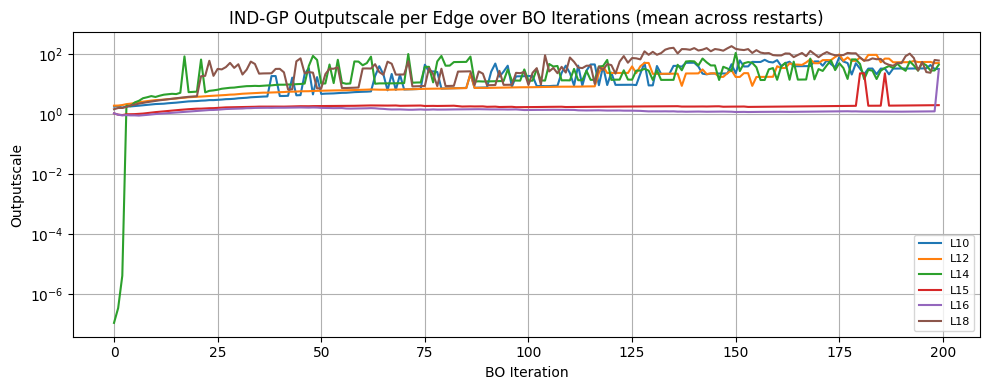

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = save_base / "results"

dfs = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    p = results_dir / f"restart_{r+1}_seed-{seed}" / "hyperparameters_per_iteration.csv"
    if p.exists():
        df = pd.read_csv(p)
        df["restart"] = r + 1
        dfs.append(df)

all_df = pd.concat(dfs, ignore_index=True)
edges = sorted(all_df["edge_id"].unique())

fig, ax = plt.subplots(figsize=(10, 4))
for eid in edges:
    m = all_df[all_df["edge_id"] == eid].groupby("iteration")["outputscale"].mean()
    ax.plot(m.index, m.values, label=eid)
ax.set_ylabel("Outputscale")
ax.set_xlabel("BO Iteration")
ax.set_yscale("log")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_title("IND-GP Outputscale per Edge over BO Iterations (mean across restarts)")
plt.tight_layout()
plt.savefig(results_dir / "indgp_outputscale_over_iterations.pdf", bbox_inches="tight")
plt.show()



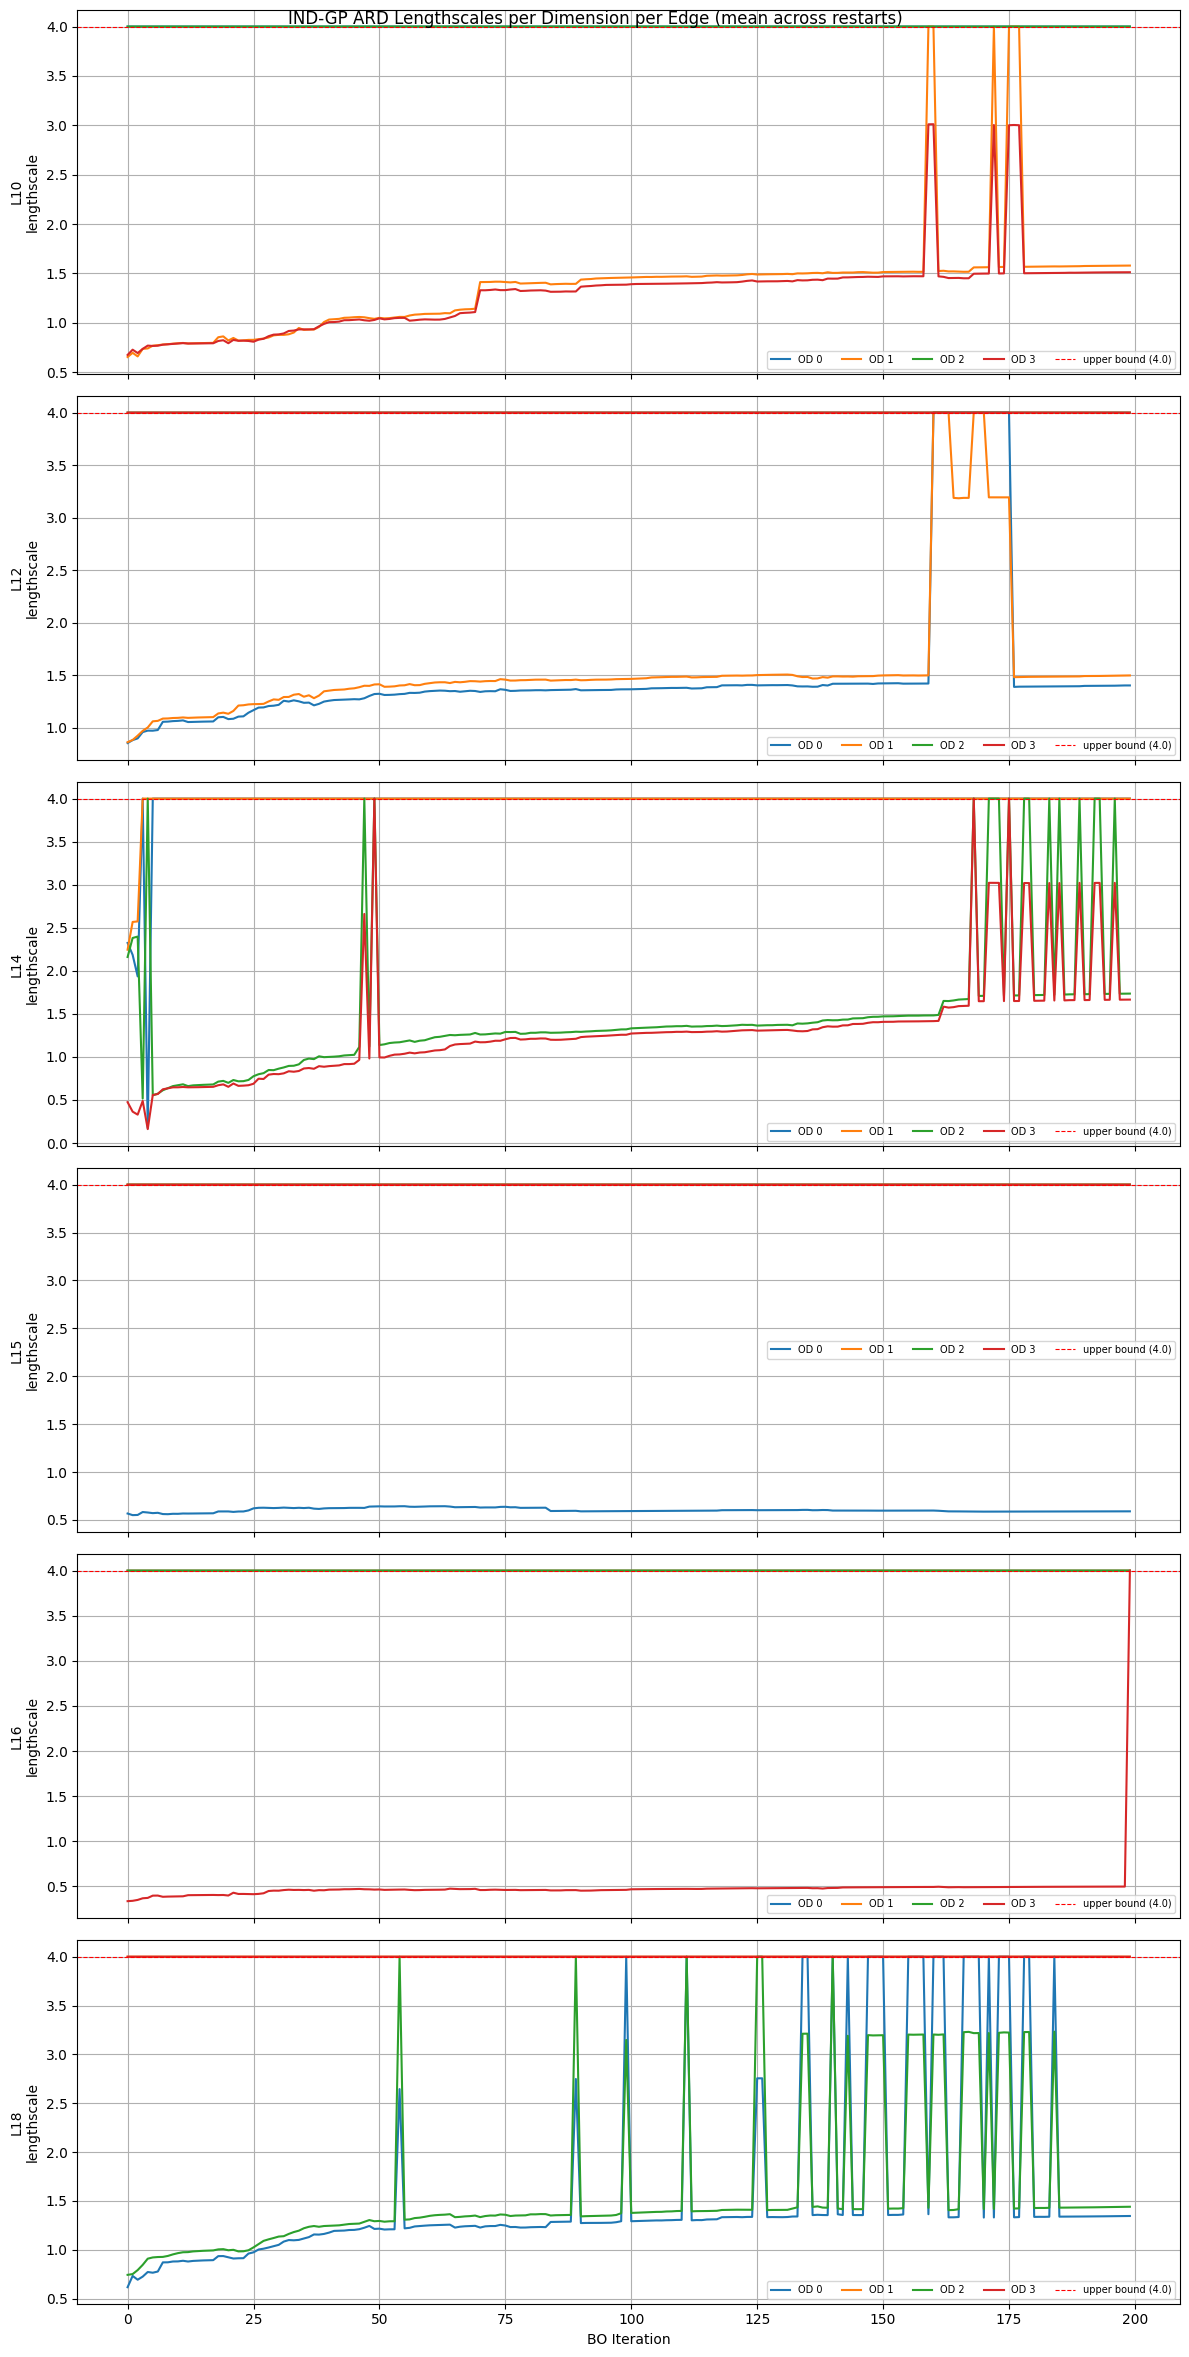

In [24]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

results_dir = save_base / "results"

dfs = []
for r in range(N_RESTARTS):
    seed = 42 + r * 1000
    p = results_dir / f"restart_{r+1}_seed-{seed}" / "hyperparameters_per_iteration.csv"
    if p.exists():
        df = pd.read_csv(p)
        df["restart"] = r + 1
        dfs.append(df)

all_df = pd.concat(dfs, ignore_index=True)
edges  = sorted(all_df["edge_id"].unique())
ls_cols = [c for c in all_df.columns if c.startswith("lengthscale_dim_")]
dims   = [c.replace("lengthscale_dim_", "OD ") for c in ls_cols]

# One subplot per edge, one line per OD dimension
fig, axes = plt.subplots(len(edges), 1, figsize=(12, 4 * len(edges)), sharex=True)
if len(edges) == 1:
    axes = [axes]

for ax, eid in zip(axes, edges):
    sub = all_df[all_df["edge_id"] == eid].groupby("iteration").mean(numeric_only=True)
    for col, dim_label in zip(ls_cols, dims):
        ax.plot(sub.index, sub[col], label=dim_label)
    ax.axhline(4.0, color="red", linestyle="--", linewidth=0.8, label="upper bound (4.0)")
    ax.set_ylabel(f"{eid}\nlengthscale")
    ax.legend(fontsize=7, ncol=len(ls_cols) + 1)
    ax.grid(True)

axes[-1].set_xlabel("BO Iteration")
fig.suptitle("IND-GP ARD Lengthscales per Dimension per Edge (mean across restarts)")
plt.tight_layout()
plt.savefig(results_dir / "indgp_lengthscales_per_dim_per_edge.pdf", bbox_inches="tight")
plt.show()


In [27]:
mean_ls = all_df.groupby("edge_id")[ls_cols].mean()
mean_ls.columns = [f"OD {i}" for i in range(len(ls_cols))]
mean_ls.index.name = "Edge"

print(mean_ls.to_string(float_format=lambda x: f"{x:.4f}"))
mean_ls.to_csv(results_dir / "indgp_mean_lengthscales.csv")




       OD 0   OD 1   OD 2   OD 3
Edge                            
L10  4.0000 1.3724 4.0000 1.2964
L12  1.5283 1.5675 4.0000 4.0000
L14  3.9531 3.9769 1.4953 1.3199
L15  0.6025 4.0000 4.0000 4.0000
L16  4.0000 4.0000 4.0000 0.4815
L18  1.6283 4.0000 1.6226 4.0000


In [33]:
mean_os = all_df.groupby("edge_id")["outputscale"].mean()
#mean_os_last = all_df[all_df["restart"] == N_RESTARTS].groupby("edge_id")["outputscale"].mean()

print("\nMean outputscale per edge:")
print(mean_os.to_string(float_format=lambda x: f"{x:.4f}"))



Mean outputscale per edge:
edge_id
L10   21.4875
L12   20.8980
L14   27.3459
L15    2.0919
L16    1.4908
L18   53.8190


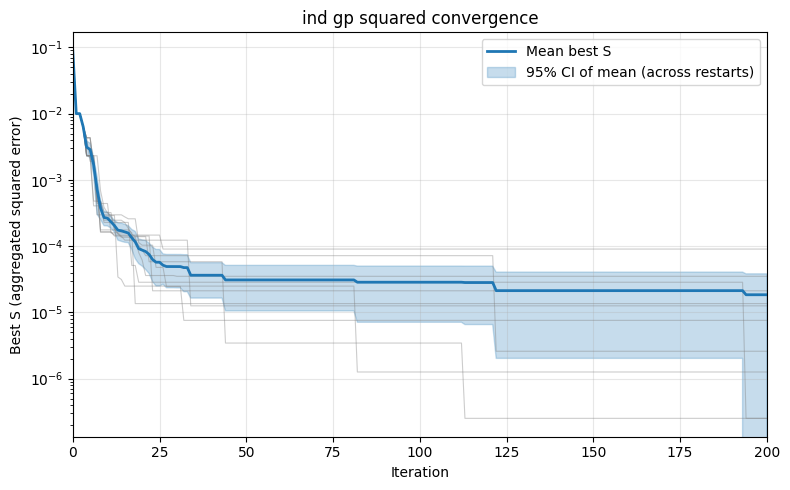

In [13]:
n_restarts = len(indgp_histories_raw)
min_len = min(len(h) for h in indgp_histories_raw)
aligned_histories = np.array([h[:min_len] for h in indgp_histories_raw])

iters = np.arange(min_len)

# Mean and standard deviation across restarts
mean_curve = aligned_histories.mean(axis=0)

if n_restarts > 1:
    std_curve = aligned_histories.std(axis=0, ddof=1) 
else:
    std_curve = np.zeros_like(mean_curve)


if n_restarts > 1:
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1)
    ci_half = t_critical * (std_curve / np.sqrt(n_restarts))
else:
    ci_half = np.zeros_like(mean_curve)




fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Individual restart curves
for h in indgp_histories_raw:
    ax.plot(
        np.arange(min(len(h), min_len)),
        h[:min_len],
        color="gray",
        alpha=0.4,
        linewidth=0.8,
    )

# Mean curve
ax.plot(
    iters,
    mean_curve,
    color="C0",
    linewidth=2,
    label="Mean best S",
)

# 95% CI of the mean
ax.fill_between(
    iters,
    mean_curve - ci_half,
    mean_curve + ci_half,
    color="C0",
    alpha=0.25,
    label="95% CI of mean (across restarts)",
)


ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (aggregated squared error)")
ax.set_title("ind gp squared convergence")
ax.set_yscale("log")
ax.set_xlim(0, min_len - 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


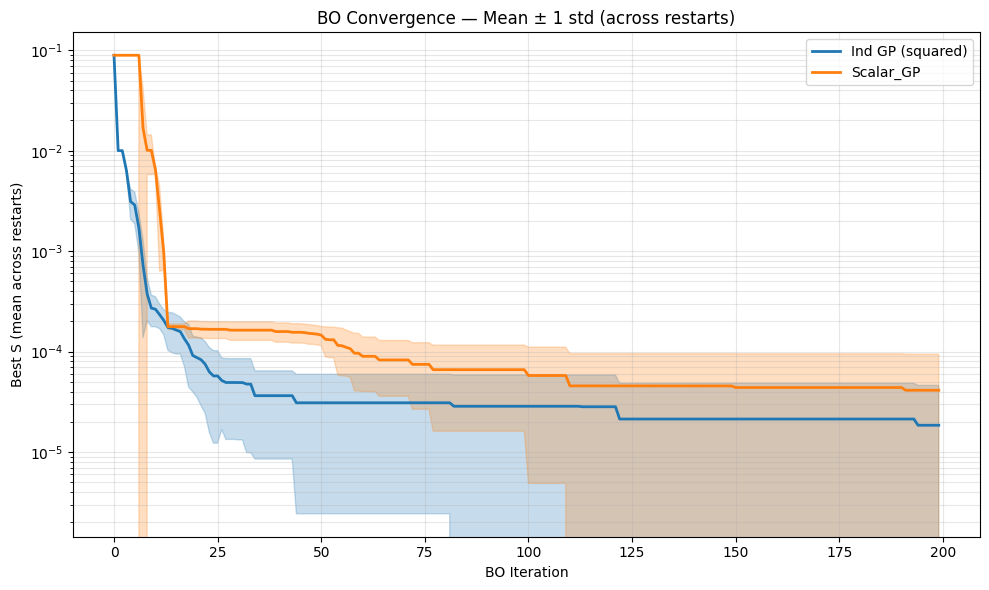

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# --- paths ---
base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path  = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"

n_show = 200

methods = {
    "Ind GP (squared)":             sim_path / "indgp_bo_squared_grouped" / "noise_1e-4_1" /"NEW"/"results"/"all_restarts_convergence.csv",
    "Scalar_GP":              sim_path / "ScalarGP" / "noise_1e-4_1" /"NEW"/"results"/"all_restarts_convergence.csv",

}

fig, ax = plt.subplots(figsize=(10, 6))

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    # --- mean ± std across restarts (axis=1 → across columns per row) ---
    mean_curve = np.nanmean(S, axis=1)
    std_curve  = np.nanstd(S, axis=1, ddof=1)

    iters = np.arange(len(mean_curve))
    line, = ax.plot(iters, mean_curve, lw=2, label=label)
    ax.fill_between(iters, mean_curve - std_curve, mean_curve + std_curve, alpha=0.25, color=line.get_color())

ax.set_yscale("log")
ax.set_xlabel("BO Iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO Convergence — Mean ± 1 std (across restarts)")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()




In [35]:
import json
import pandas as pd
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "NEW" / "results"
with open(results_dir / "hyperparameters_last_iteration.json") as f:
    data = json.load(f)

print("Summary (across edges):", data["summary"])
df = pd.DataFrame(data["per_edge"])
print("\nPer-edge (grouped edge IDs):")
display(df)  # or print(df)
# df.to_csv(results_dir / "hyperparameters_per_edge.csv", index=False)

Summary (across edges): {'lengthscale_mean': 2.886059440291257, 'lengthscale_std': 0.183155294297241, 'lengthscale_min': 2.6965531024552103, 'lengthscale_max': 3.147468519813764, 'outputscale_mean': 9.04700435461, 'outputscale_std': 5.994653359603955, 'outputscale_min': 1.2542075756468811, 'outputscale_max': 18.498671607906335, 'noise_mean': 0.00010000000885119922, 'noise_std': 2.482115414849446e-11, 'noise_min': 9.999999747380946e-05, 'noise_max': 0.00010000006434937311}

Per-edge (grouped edge IDs):


,edge_id,lengthscale,outputscale,noise
0,L12,"[1.4011648230950935, 1.4965054045488706, 3.999...",10.006297,0.0001
1,L14,"[3.99999225701427, 3.999981101925639, 1.735789...",18.498672,0.0001
2,L18,"[1.3457083373654162, 3.999999037917482, 1.4405...",9.899380,0.0001
3,L10,"[3.9999990915285206, 1.5797978191415016, 3.999...",12.691531,0.0001
4,L15,"[0.5898758948459533, 3.999999341792526, 3.9999...",1.931939,0.0001
5,L16,"[3.9999999893600533, 3.99999898751368, 3.99999...",1.254208,0.0001


         gt_flow   sim_std  sq_err_mean  sq_err_std
edge_id                                            
L14       1800.0  473.6340       0.0691      0.1798
L10       1400.0  403.2824       0.0831      0.2453
L18       1400.0  437.0211       0.0973      0.2175
L12       1000.0  345.2195       0.1197      0.3079
L16        900.0  286.8113       0.1011      0.2325
L15        500.0  205.3287       0.1678      0.5854


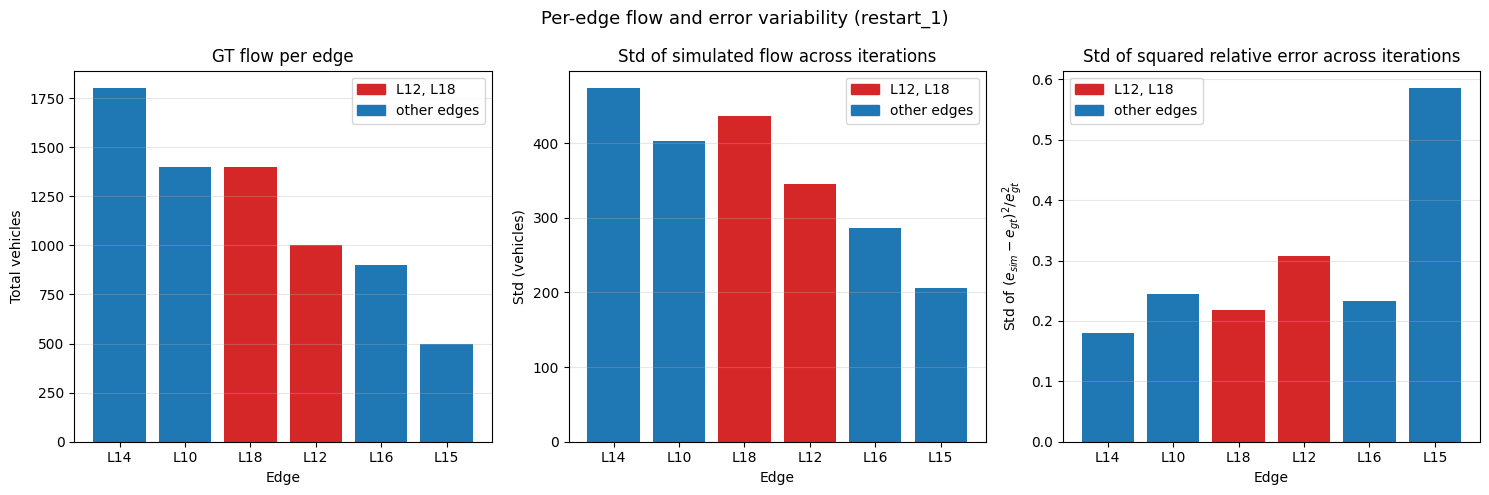

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

restart_dir = Path("output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW/restart_1_seed-42")

records = []
for it_dir in sorted(restart_dir.glob("iter_*"), key=lambda p: int(p.name.split("_")[1])):
    csv = it_dir / "link_measure_compare.csv"
    if csv.exists():
        df = pd.read_csv(csv)
        df["iteration"] = int(it_dir.name.split("_")[1])
        records.append(df)

all_df = pd.concat(records, ignore_index=True)
all_df["sq_rel_err"] = ((all_df["interval_nVehContrib_sim"] - all_df["interval_nVehContrib_gt"]) 
                         / all_df["interval_nVehContrib_gt"]) ** 2

edges = all_df["edge_id"].unique()
gt_flow = all_df.groupby("edge_id")["interval_nVehContrib_gt"].first()
sim_std = all_df.groupby("edge_id")["interval_nVehContrib_sim"].std()
err_std = all_df.groupby("edge_id")["sq_rel_err"].std()
err_mean = all_df.groupby("edge_id")["sq_rel_err"].mean()

summary = pd.DataFrame({
    "gt_flow": gt_flow,
    "sim_std": sim_std,
    "sq_err_mean": err_mean,
    "sq_err_std": err_std,
}).sort_values("gt_flow", ascending=False)

print(summary.round(4))

# --- Figure: 3 subplots ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = ["C3" if e in ["L12", "L18"] else "C0" for e in summary.index]

# 1. GT flow per edge
axes[0].bar(summary.index, summary["gt_flow"], color=colors)
axes[0].set_title("GT flow per edge")
axes[0].set_ylabel("Total vehicles")
axes[0].set_xlabel("Edge")

# 2. Std of simulated flow across iterations
axes[1].bar(summary.index, summary["sim_std"], color=colors)
axes[1].set_title("Std of simulated flow across iterations")
axes[1].set_ylabel("Std (vehicles)")
axes[1].set_xlabel("Edge")

# 3. Std of squared relative error across iterations
axes[2].bar(summary.index, summary["sq_err_std"], color=colors)
axes[2].set_title("Std of squared relative error across iterations")
axes[2].set_ylabel("Std of $(e_{sim} - e_{gt})^2 / e_{gt}^2$")
axes[2].set_xlabel("Edge")

for ax in axes:
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color="C3", label="L12, L18"), Patch(color="C0", label="other edges")])
    ax.grid(True, alpha=0.3, axis="y")

plt.suptitle("Per-edge flow and error variability (restart_1)", fontsize=13)
plt.tight_layout()
plt.show()


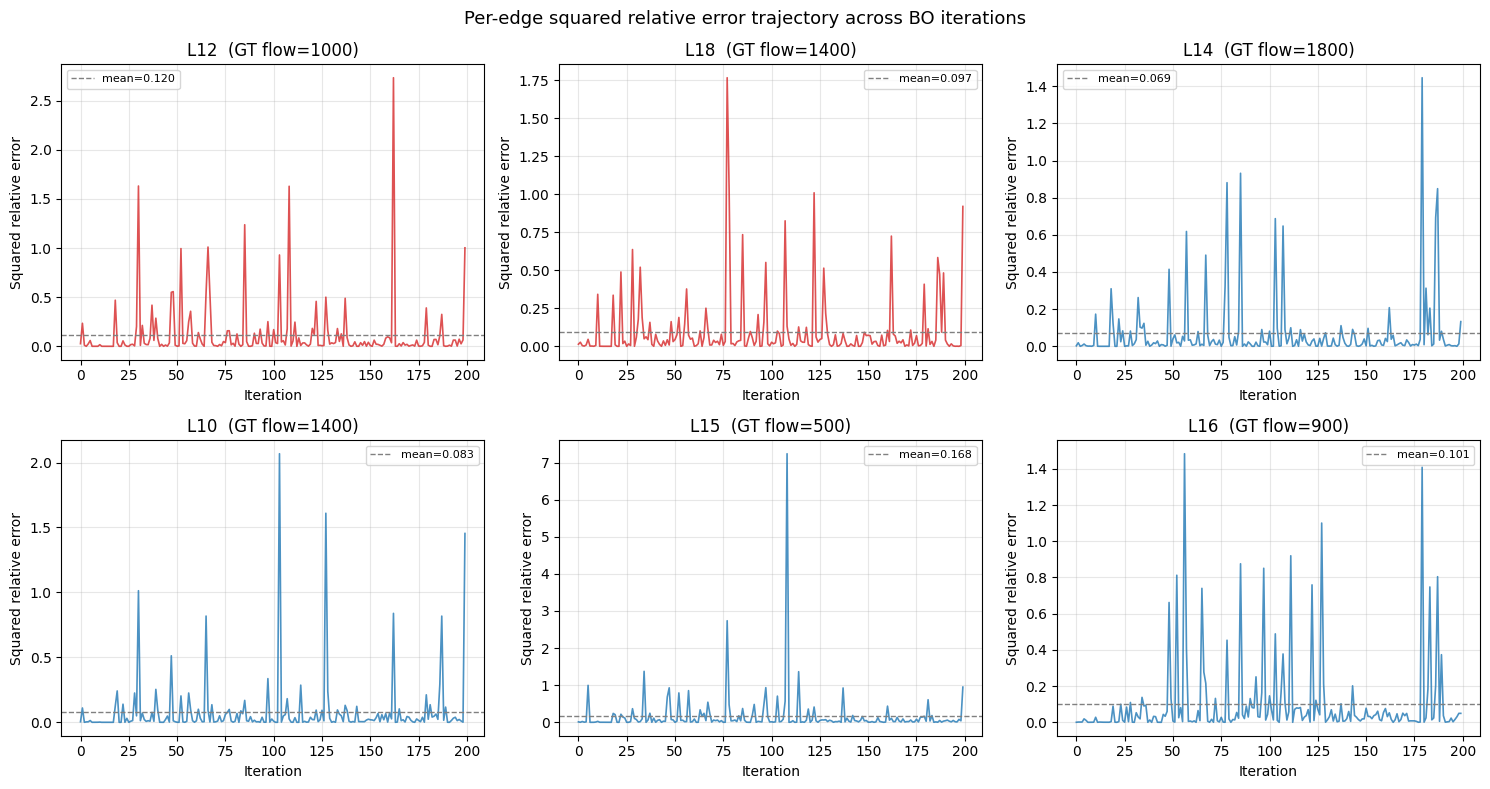

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

edge_order = ["L12", "L18", "L14", "L10", "L15", "L16"]

for ax, edge in zip(axes, edge_order):
    edge_df = all_df[all_df["edge_id"] == edge].sort_values("iteration")
    
    ax.plot(edge_df["iteration"], edge_df["sq_rel_err"], 
            color="C3" if edge in ["L12", "L18"] else "C0",
            linewidth=1.2, alpha=0.8)
    
    ax.axhline(edge_df["sq_rel_err"].mean(), linestyle="--", 
               color="gray", linewidth=1, label=f"mean={edge_df['sq_rel_err'].mean():.3f}")
    
    gt = edge_df["interval_nVehContrib_gt"].iloc[0]
    ax.set_title(f"{edge}  (GT flow={gt:.0f})")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Squared relative error")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Per-edge squared relative error trajectory across BO iterations", fontsize=13)
plt.tight_layout()
plt.show()


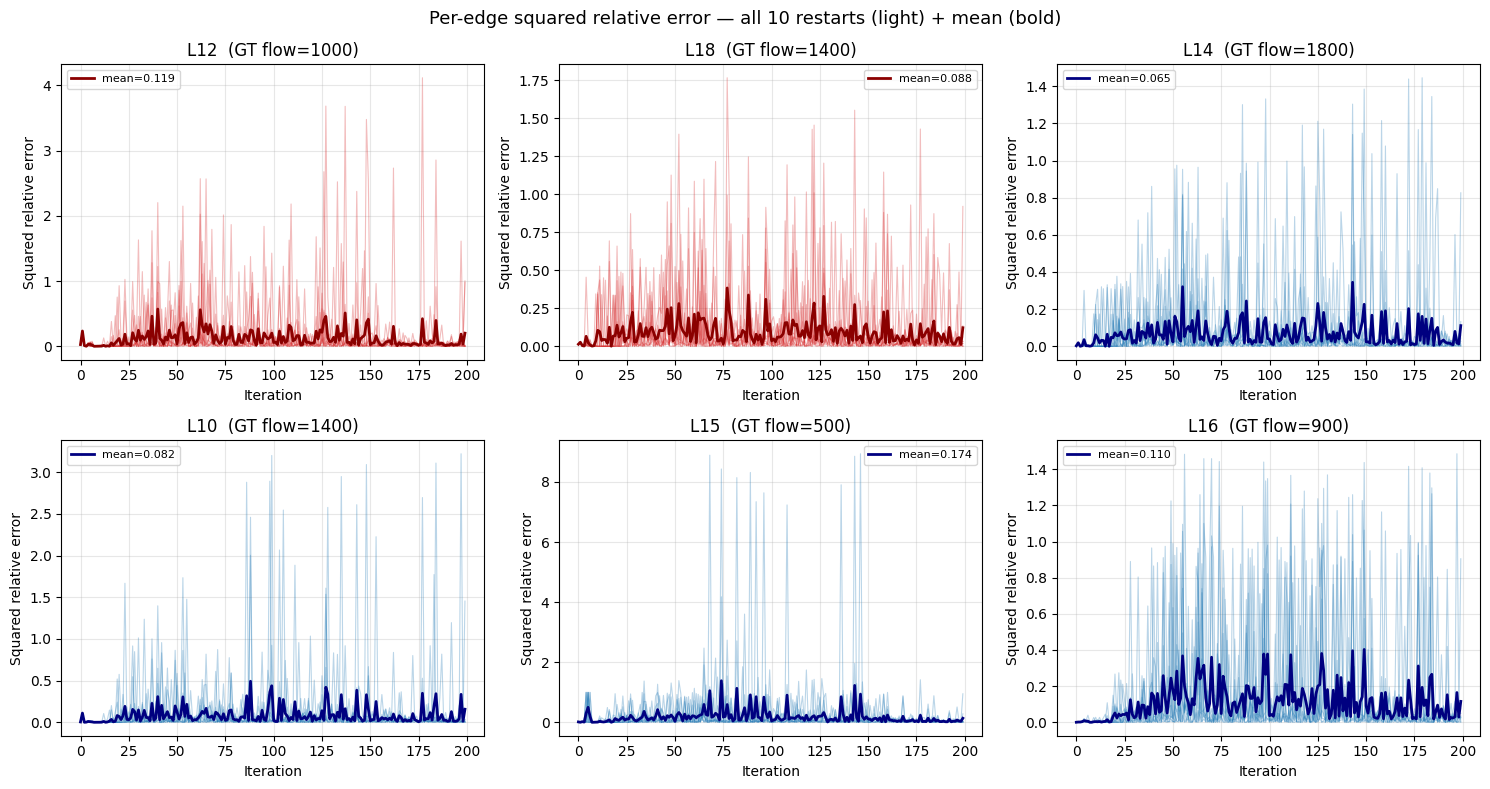

In [23]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base = Path("output/quickstart_bo_vanilla_matern-2p5/indgp_bo_squared_grouped/noise_1e-4_1/NEW")
restart_dirs = sorted(base.glob("restart_*"))

# Collect all data across restarts
all_records = []
for rd in restart_dirs:
    restart_id = rd.name
    for it_dir in sorted(rd.glob("iter_*"), key=lambda p: int(p.name.split("_")[1])):
        csv = it_dir / "link_measure_compare.csv"
        if csv.exists():
            df = pd.read_csv(csv)
            df["iteration"] = int(it_dir.name.split("_")[1])
            df["restart"] = restart_id
            all_records.append(df)

all_df = pd.concat(all_records, ignore_index=True)
all_df["sq_rel_err"] = ((all_df["interval_nVehContrib_sim"] - all_df["interval_nVehContrib_gt"])
                         / all_df["interval_nVehContrib_gt"]) ** 2

edge_order = ["L12", "L18", "L14", "L10", "L15", "L16"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, edge in zip(axes, edge_order):
    edge_df = all_df[all_df["edge_id"] == edge]

    # Plot each restart individually
    for rid, group in edge_df.groupby("restart"):
        group = group.sort_values("iteration")
        ax.plot(group["iteration"], group["sq_rel_err"],
                color="C3" if edge in ["L12", "L18"] else "C0",
                alpha=0.3, linewidth=0.8)

    # Plot mean across restarts
    mean_df = edge_df.groupby("iteration")["sq_rel_err"].mean()
    ax.plot(mean_df.index, mean_df.values,
            color="darkred" if edge in ["L12", "L18"] else "navy",
            linewidth=2, label=f"mean={mean_df.mean():.3f}")

    gt = edge_df["interval_nVehContrib_gt"].iloc[0]
    ax.set_title(f"{edge}  (GT flow={gt:.0f})")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Squared relative error")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

n_restarts = len(restart_dirs)
plt.suptitle(f"Per-edge squared relative error — all {n_restarts} restarts (light) + mean (bold)", fontsize=13)
plt.tight_layout()
plt.show()


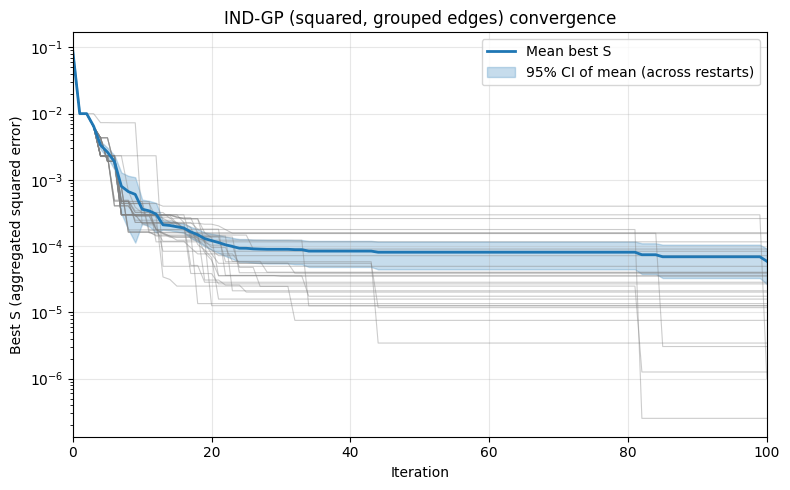

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path
import pandas as pd

BO_FOLDER = "indgp_bo_squared_grouped"
NOISE_LABEL = "noise_1e-4_1"
results_dir = Path(config["simulation_run_path"]) / BO_FOLDER / NOISE_LABEL / "results"

indgp_histories_raw = []
for r in range(100):  
    restart_seed = 42 + r * 1000
    conv_path = results_dir / f"restart_{r+1}_seed-{restart_seed}" / "convergence.csv"
    if not conv_path.exists():
        break
    df = pd.read_csv(conv_path)
    indgp_histories_raw.append(df["best_S"].values)

n_restarts = len(indgp_histories_raw)
assert n_restarts >= 1, f"No convergence files found under {results_dir}"

min_len = min(len(h) for h in indgp_histories_raw) # lenghth  of the shortest convergence file
aligned = np.array([h[:min_len] for h in indgp_histories_raw])
iters = np.arange(min_len)

mean_curve = aligned.mean(axis=0) # at each iteration, the mean of the best S across all restarts
std_curve = aligned.std(axis=0, ddof=1)
t_critical = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0 # 95% confidence interval
ci_half = t_critical * (std_curve / np.sqrt(n_restarts)) if n_restarts > 1 else np.zeros_like(mean_curve)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

for h in indgp_histories_raw:
    ax.plot(np.arange(min_len), h[:min_len], color="gray", alpha=0.4, linewidth=0.8)

ax.plot(iters, mean_curve, color="C0", linewidth=2, label="Mean best S")
if n_restarts > 1:
    ax.fill_between(
        iters, mean_curve - ci_half, mean_curve + ci_half,
        color="C0", alpha=0.25, label="95% CI of mean (across restarts)",
    )

ax.set_xlabel("Iteration")
ax.set_ylabel("Best S (aggregated squared error)")
ax.set_title("IND-GP (squared, grouped edges) convergence")
ax.set_yscale("log")
ax.set_xlim(0, min_len - 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

=== % iterations AT upper bound (4.0) per edge ===
edge_id
L10    100.0000
L12    100.0000
L15    100.0000
L16    100.0000
L18    100.0000
L14     98.4008


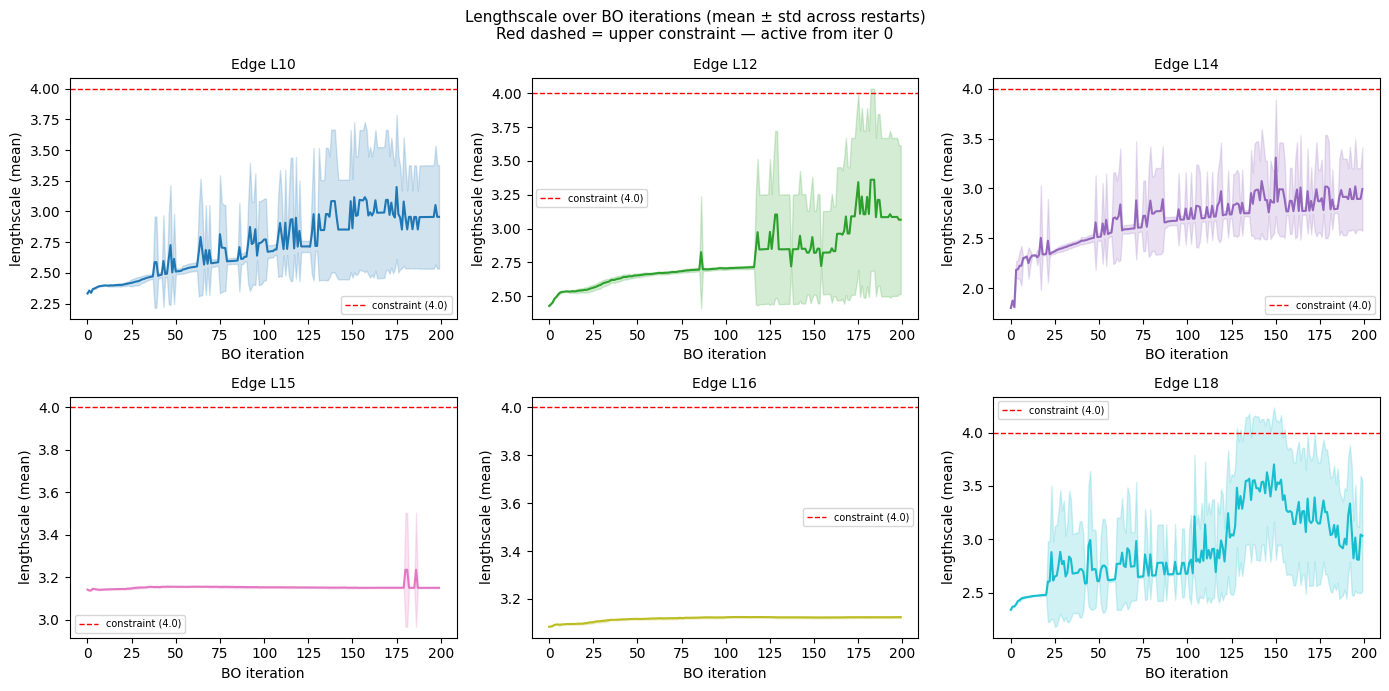

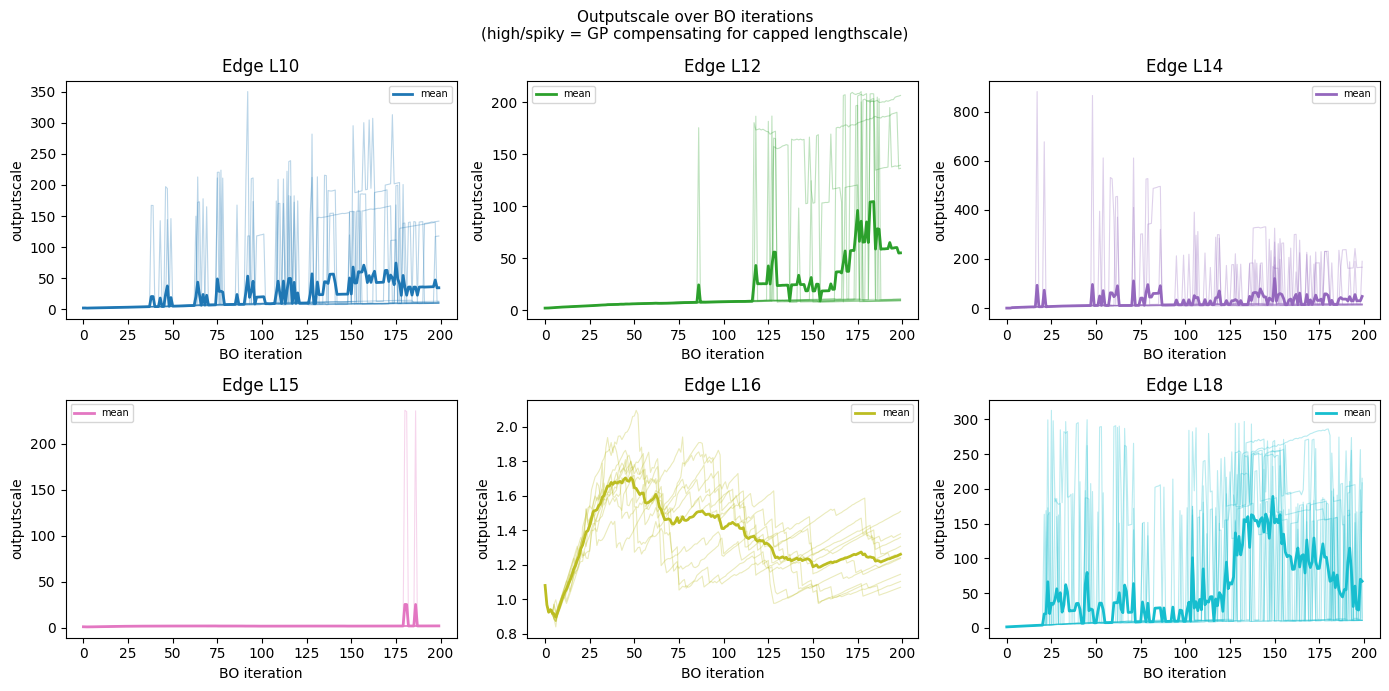

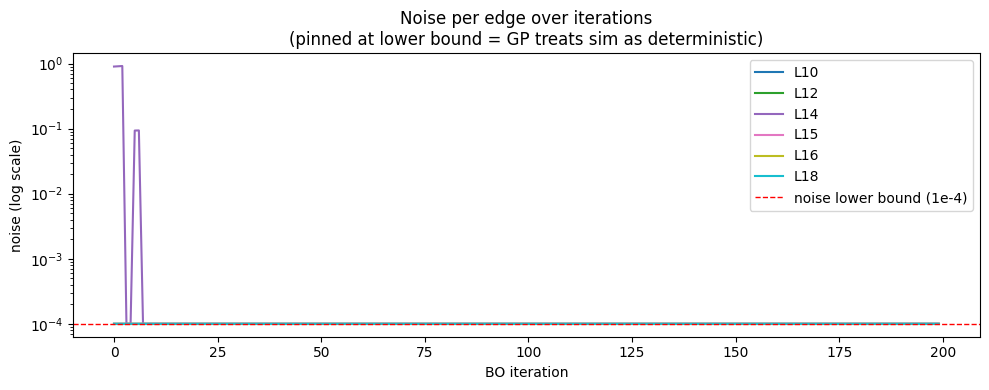


=== DIAGNOSIS ===
Lengthscale: all edges pinned at upper bound (4.0) from iter 0.
  → True optimal lengthscale > 4.0: the error surface is very smooth.
  → Consider relaxing the constraint, e.g. Interval(0.005, 10.0).

Noise: 5/6 edges pinned at lower bound (1e-4).
  → GP correctly identifies SUMO as a deterministic simulator. OK.

Outputscale: high variance, especially L10, L12, L14, L18.
  → GP inflates amplitude to compensate for capped lengthscale.


In [22]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from pathlib import Path
import importlib
import src.models.gp_models as gp_models
importlib.reload(gp_models)

from src.models.gp_models import load_all_hyperparameters

from src.models.gp_models import load_all_hyperparameters

import importlib, src.models.gp_models as _gp
importlib.reload(_gp)
from src.models.gp_models import load_all_hyperparameters

all_hp = load_all_hyperparameters(
    config["simulation_run_path"], BO_FOLDER, NOISE_LABEL, run_subfolder="NEW"
)
edge_ids = sorted(all_hp["edge_id"].unique())
restarts  = sorted(all_hp["restart"].unique())
UPPER_BOUND = 4.0
colors = cm.tab10(np.linspace(0, 1, len(edge_ids)))

# ── 1. Lengthscale at constraint bound ───────────────────────────────────────
at_bound = (
    all_hp.groupby("edge_id")["lengthscale_max"]
    .apply(lambda x: (x >= UPPER_BOUND - 0.01).mean() * 100)
)
print("=== % iterations AT upper bound (4.0) per edge ===")
print(at_bound.sort_values(ascending=False).to_string())

# ── 2. Lengthscale over iterations (mean ± std across restarts) ──────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=False)
axes = axes.flatten()
for ax, (eid, c) in zip(axes, zip(edge_ids, colors)):
    sub = all_hp[all_hp["edge_id"] == eid]
    pivot = sub.pivot_table(index="iteration", columns="restart", values="lengthscale_mean")
    mean_ls = pivot.mean(axis=1)
    std_ls  = pivot.std(axis=1)
    ax.fill_between(mean_ls.index, mean_ls - std_ls, mean_ls + std_ls, alpha=0.2, color=c)
    ax.plot(mean_ls.index, mean_ls, color=c, lw=1.5)
    ax.axhline(UPPER_BOUND, color="red", ls="--", lw=1, label="constraint (4.0)")
    ax.set_title(f"Edge {eid}", fontsize=10)
    ax.set_xlabel("BO iteration"); ax.set_ylabel("lengthscale (mean)")
    ax.legend(fontsize=7)
fig.suptitle("Lengthscale over BO iterations (mean ± std across restarts)\n"
             "Red dashed = upper constraint — active from iter 0", fontsize=11)
plt.tight_layout(); plt.show()

# ── 3. Outputscale over iterations ───────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()
for ax, (eid, c) in zip(axes, zip(edge_ids, colors)):
    sub = all_hp[all_hp["edge_id"] == eid]
    pivot = sub.pivot_table(index="iteration", columns="restart", values="outputscale")
    mean_os = pivot.mean(axis=1)
    for r in pivot.columns:
        ax.plot(pivot.index, pivot[r], alpha=0.3, lw=0.8, color=c)
    ax.plot(mean_os.index, mean_os, color=c, lw=2, label="mean")
    ax.set_title(f"Edge {eid}"); ax.set_xlabel("BO iteration"); ax.set_ylabel("outputscale")
    ax.legend(fontsize=7)
fig.suptitle("Outputscale over BO iterations\n(high/spiky = GP compensating for capped lengthscale)", fontsize=11)
plt.tight_layout(); plt.show()

# ── 4. Noise over iterations ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
for eid, c in zip(edge_ids, colors):
    sub = all_hp[all_hp["edge_id"] == eid]
    pivot = sub.pivot_table(index="iteration", columns="restart", values="noise").mean(axis=1)
    ax.plot(pivot.index, pivot, label=eid, color=c, lw=1.5)
ax.axhline(1e-4, color="red", ls="--", lw=1, label="noise lower bound (1e-4)")
ax.set_yscale("log"); ax.set_xlabel("BO iteration"); ax.set_ylabel("noise (log scale)")
ax.set_title("Noise per edge over iterations\n(pinned at lower bound = GP treats sim as deterministic)")
ax.legend(); plt.tight_layout(); plt.show()

# ── 5. Diagnosis summary ──────────────────────────────────────────────────────
print("\n=== DIAGNOSIS ===")
print(f"Lengthscale: all edges pinned at upper bound ({UPPER_BOUND}) from iter 0.")
print("  → True optimal lengthscale > 4.0: the error surface is very smooth.")
print("  → Consider relaxing the constraint, e.g. Interval(0.005, 10.0).")
print()
print("Noise: 5/6 edges pinned at lower bound (1e-4).")
print("  → GP correctly identifies SUMO as a deterministic simulator. OK.")
print()
print("Outputscale: high variance, especially L10, L12, L14, L18.")
print("  → GP inflates amplitude to compensate for capped lengthscale.")


# LOO-CV + Calibration validation | Ind GP

Fitting 6 independent GPs on N=210 points for LOO validation...
All 6 GPs fitted


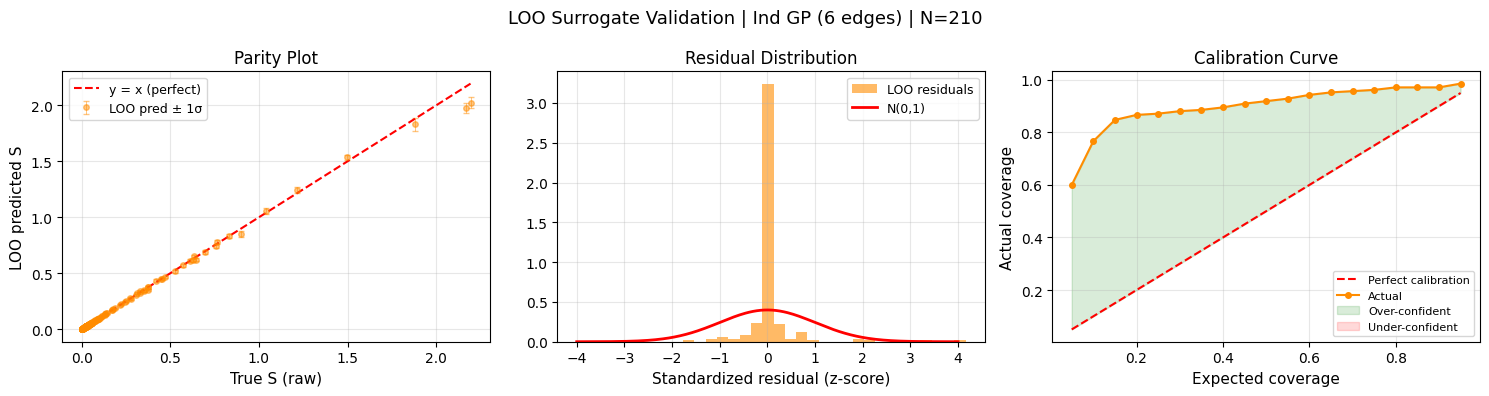


=== LOO-CV Results (Ind GP) ===
  RMSE:          0.018905
  MAE:           0.003650
  Within 1σ:     95.2%  (ideal: 68%)
  Within 2σ:     98.6%  (ideal: 95%)
  ⚠ Underconfident: uncertainty too wide → EI will over-explore


In [38]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy import stats as _stats
from botorch.utils.transforms import normalize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood

# ─── Setup: use final training data from Ind GP (last restart in scope) ──────
# train_X_ind [N, d], train_Y_ind [N, L], weights_t [L], bounds, kernel, device, dtype
N = train_X_ind.shape[0]
L = train_Y_ind.shape[1]
train_X_norm_val = normalize(train_X_ind, bounds=bounds)
train_S_val = (train_Y_ind * weights_t).sum(dim=1)   # [N] true aggregated S

# ─── Fit L independent GPs on all training data ──────────────────────────────
print(f"Fitting {L} independent GPs on N={N} points for LOO validation...")
ind_val, mlls_val = initialize_independent_gp_models_with_modellist(
    train_X_norm_val, train_Y_ind, kernel=kernel
)
ind_val = ind_val.to(device=device, dtype=dtype)
for mll_l in mlls_val:
    mll_l = mll_l.to(device=device, dtype=dtype)
for gp_l, mll_l in zip(ind_val.models, mlls_val):
    gp_l.train(); mll_l.train()
    fit_gpytorch_mll(mll_l)
    gp_l.eval()
print(f"All {L} GPs fitted")

# ─── LOO per GP, aggregate into scalar S ─────────────────────────────────────
# For each GP_l:  C_l = K_l + noise_l*I  (in standardized space)
#   loo_mu_l_std  = y_l_std - (C_l_inv @ y_l_std) / diag(C_l_inv)
#   loo_var_l_std = 1 / diag(C_l_inv)
# De-standardize:  loo_mu_l_raw  = loo_mu_l_std * std_l + mean_l
#                  loo_var_l_raw = loo_var_l_std * std_l^2
# Aggregate:       mu_S  = sum_l  w_l  * loo_mu_l_raw
#                  var_S = sum_l  w_l^2 * loo_var_l_raw
mu_loo_S  = torch.zeros(N, dtype=dtype, device=device)
var_loo_S = torch.zeros(N, dtype=dtype, device=device)

with torch.no_grad():
    for l, (gp_l, w_l) in enumerate(zip(ind_val.models, weights_t)):
        K_l     = gp_l.covar_module(train_X_norm_val).evaluate()   # [N, N]
        noise_l = gp_l.likelihood.noise.squeeze()

        mean_l = gp_l.outcome_transform.means.squeeze()             # scalar
        std_l  = gp_l.outcome_transform.stdvs.squeeze()             # scalar
        y_l_std = (train_Y_ind[:, l] - mean_l) / std_l             # [N]

        C_l     = K_l + noise_l * torch.eye(N, dtype=dtype, device=device)
        C_l_inv = torch.linalg.inv(C_l)
        alpha_l = C_l_inv @ y_l_std
        diag_l  = C_l_inv.diagonal().clamp_min(1e-8)

        loo_mu_l_std  = y_l_std - alpha_l / diag_l                  # [N]
        loo_var_l_std = (1.0 / diag_l).clamp_min(0)                # [N] variance

        loo_mu_l_raw  = loo_mu_l_std * std_l + mean_l
        loo_var_l_raw = loo_var_l_std * std_l ** 2

        mu_loo_S  += w_l * loo_mu_l_raw
        var_loo_S += w_l ** 2 * loo_var_l_raw

loo_means_np = mu_loo_S.cpu().numpy()
loo_stds_np  = var_loo_S.clamp_min(0).sqrt().cpu().numpy()
train_S_np   = train_S_val.cpu().numpy()
residuals    = (train_S_np - loo_means_np) / loo_stds_np

# ─── Plots ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(f"LOO Surrogate Validation | Ind GP ({L} edges) | N={N}", fontsize=13)

# 1. Parity plot
ax = axes[0]
mn = min(train_S_np.min(), loo_means_np.min())
mx = max(train_S_np.max(), loo_means_np.max())
ax.errorbar(train_S_np, loo_means_np, yerr=loo_stds_np,
            fmt='o', ms=4, alpha=0.5, color='darkorange',
            ecolor='darkorange', elinewidth=0.7, capsize=2, label='LOO pred \u00b1 1\u03c3')
ax.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='y = x (perfect)')
ax.set_xlabel('True S (raw)', fontsize=11)
ax.set_ylabel('LOO predicted S', fontsize=11)
ax.set_title('Parity Plot')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# 2. Standardized residuals histogram
ax = axes[1]
ax.hist(residuals, bins=25, density=True, alpha=0.6, color='darkorange', label='LOO residuals')
x_r = np.linspace(-4, 4, 200)
ax.plot(x_r, np.exp(-0.5 * x_r**2) / np.sqrt(2 * np.pi), 'r-', lw=2, label='N(0,1)')
ax.set_xlabel('Standardized residual (z-score)', fontsize=11)
ax.set_title('Residual Distribution')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# 3. Calibration curve
ax = axes[2]
levels = np.linspace(0.05, 0.95, 19)
coverage = [np.mean(np.abs(residuals) <= _stats.norm.ppf((1 + lv) / 2)) for lv in levels]
above = np.array(coverage) >= levels
ax.plot(levels, levels, 'r--', lw=1.5, label='Perfect calibration')
ax.plot(levels, coverage, 'o-', color='darkorange', ms=4, label='Actual')
ax.fill_between(levels, levels, coverage, where=above, alpha=0.15, color='green', label='Over-confident')
ax.fill_between(levels, levels, coverage, where=~above, alpha=0.15, color='red', label='Under-confident')
ax.set_xlabel('Expected coverage', fontsize=11)
ax.set_ylabel('Actual coverage', fontsize=11)
ax.set_title('Calibration Curve')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ─── Summary stats ────────────────────────────────────────────────────────────
rmse = np.sqrt(np.mean((train_S_np - loo_means_np) ** 2))
mae  = np.mean(np.abs(train_S_np - loo_means_np))
p68  = np.mean(np.abs(residuals) <= 1.00) * 100
p95  = np.mean(np.abs(residuals) <= 1.96) * 100
print("\n=== LOO-CV Results (Ind GP) ===")
print(f"  RMSE:          {rmse:.6f}")
print(f"  MAE:           {mae:.6f}")
print(f"  Within 1\u03c3:     {p68:.1f}%  (ideal: 68%)")
print(f"  Within 2\u03c3:     {p95:.1f}%  (ideal: 95%)")
if p68 < 50:
    print("  \u26a0 Overconfident: uncertainty too narrow \u2192 EI may over-exploit")
elif p68 > 85:
    print("  \u26a0 Underconfident: uncertainty too wide \u2192 EI will over-explore")
else:
    print("  \u2713 Calibration looks reasonable")


In [39]:
print(f"S min:   {train_Y_ind.min().item():.6f}")
print(f"S max:   {train_Y_ind.max().item():.6f}")
print(f"S range: {(train_Y_ind.max() - train_Y_ind.min()).item():.6f}")


S min:   0.000000
S max:   8.940100
S range: 8.940100


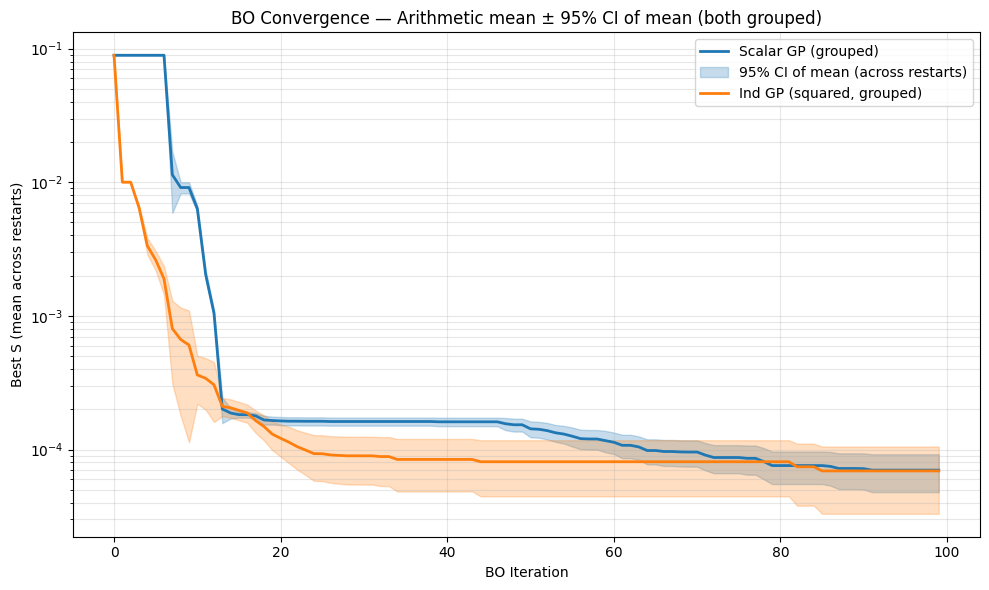

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from pathlib import Path
import pandas as pd

# --- paths (match where your runs save) ---
base_path = Path("/Users/inesbenhamza/Desktop/Sumo_od_calibration_bn")
sim_path = base_path / "output" / "quickstart_bo_vanilla_matern-2p5"

n_show = 100

methods = {
    "Scalar GP (grouped)": sim_path / "ScalarGP" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
    "Ind GP (squared, grouped)": sim_path / "indgp_bo_squared_grouped" / "noise_1e-4_1" / "results" / "all_restarts_convergence.csv",
}

fig, ax = plt.subplots(figsize=(10, 6))
first_method = True  # to add "95% CI of mean" label only once

for label, path in methods.items():
    if not path.exists():
        print(f"Skip {label}: not found at {path}")
        continue

    df = pd.read_csv(path).head(n_show)

    restart_cols = [c for c in df.columns if c.startswith("restart_")]
    if restart_cols:
        S = df[restart_cols].to_numpy(dtype=float)
    elif "mean" in df.columns:
        S = df[["mean"]].to_numpy(dtype=float)
    elif "best_S" in df.columns:
        S = df[["best_S"]].to_numpy(dtype=float)
    else:
        print(f"Skip {label}: no restart_*, mean, or best_S column")
        continue

    # Arithmetic mean and 95% CI of mean (same as Ind-GP-only plot)
    n_restarts = S.shape[1]
    mean_curve = np.nanmean(S, axis=1)
    std_curve = np.nanstd(S, axis=1, ddof=1) if n_restarts > 1 else np.zeros(len(mean_curve))
    t_critical = stats.t.ppf(0.975, df=n_restarts - 1) if n_restarts > 1 else 0
    ci_half = t_critical * (std_curve / np.sqrt(n_restarts)) if n_restarts > 1 else np.zeros_like(mean_curve)

    iters = np.arange(len(mean_curve))
    line, = ax.plot(iters, mean_curve, lw=2, label=label)
    if n_restarts > 1:
        ci_label = "95% CI of mean (across restarts)" if first_method else None
        ax.fill_between(
            iters, mean_curve - ci_half, mean_curve + ci_half,
            alpha=0.25, color=line.get_color(), label=ci_label,
        )
        first_method = False

ax.set_yscale("log")
ax.set_xlabel("BO Iteration")
ax.set_ylabel("Best S (mean across restarts)")
ax.set_title("BO Convergence — Arithmetic mean ± 95% CI of mean (both grouped)")
ax.grid(True, alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

In [1]:
import json
from pathlib import Path

results_dir = Path(config["simulation_run_path"]) / BO_FOLDER / NOISE_LABEL / "results"
hp_path = results_dir / "hyperparameters_last_iteration.json"

if hp_path.exists():
    with open(hp_path) as f:
        hp = json.load(f)
    summary = hp["summary"]
    print("Ind GP hyperparameters (last restart, last iter):")
    print(f"  Noise:  min={summary['noise_min']:.6e}, max={summary['noise_max']:.6e}, mean={summary['noise_mean']:.6e}")
    print(f"  Lengthscale: min={summary['lengthscale_min']:.4f}, max={summary['lengthscale_max']:.4f}")
    # Per-edge noise
    import pandas as pd
    df = pd.DataFrame(hp["per_edge"])
    print(df[["edge_id", "noise"]].to_string())
else:
    print(f"Not found: {hp_path} (run at least one full Ind GP BO restart first)")

NameError: name 'config' is not defined